# Dominica 2026 Article IV: from IMF PDF to dashboard with two LLMs

**Student:** Prashanth Madduri (SRN 24155712). **Allocation:** Dominica, 2025-2026.
**Report:** IMF Country Report No. 26/117, *Dominica: 2026 Article IV Consultation, Press Release; Staff Report; and Statement by the Executive Director for Dominica* (June 2026, 98 pages).

This notebook runs the whole coursework pipeline in order:

| Part | What it does | Main output |
|---|---|---|
| Setup | writes and imports the helper module `dominica_kit.py`, picks the LLM backend | `cache/llm.sqlite` |
| Task 1 | reads the PDF with pypdf, cleans it, finds the sections, makes 300-token chunks, summarises each section, writes an executive summary, has a second model judge and revise | `section_summaries.json`, `executive_summary.json` |
| Task 2 | theme counts (lexicon plus LLM labels), strengths and vulnerabilities with checked quotes, the indicator JSON with a judge audit and my own hand check, time series read from the statistical tables | `themes.json`, `strengths_vulnerabilities.json`, `indicators.json`, `indicator_audit.json`, `timeseries.json` |
| Task 3 | retrieval with sentence-transformers and FAISS, nine test questions scored by code and by the judge | `rag_eval.json` |
| Extension | multi-query retrieval with MMR against single-query retrieval on the same nine questions | `extension_multiquery.json` |
| Task 4 | `pd.melt` to long format and a six-panel dashboard at 300 dpi | `outputs/figures/dashboard.png` |
| Run record | every prompt and the full call log | `run_record.json`, `call_log.json` |

**How to run in Colab.** Upload the folder `data/` (it holds `dominica_cr26117.pdf`) next to this notebook, and `cache/` too if you have it, then choose *Runtime > Run all*. All paths are relative to the notebook folder.

**Models.** Writer `google/gemini-3.6-flash`, judge `google/gemini-3.8-flash`. The backend is chosen by code: `gemini_api` when a Colab secret called `GEMINI_API_KEY` exists, otherwise `colab` (Colab's built-in model proxy), otherwise `replay`, which only reads replies already stored in `cache/llm.sqlite`. With the cache uploaded, a rerun makes no live calls at all.

## Setup

> **What happens here:** Colab already has pandas, numpy, matplotlib, pydantic, scipy, sentence-transformers, openai and google-genai. Only `pypdf` and `faiss-cpu` are missing, so only those two are installed, at the versions pinned in `requirements.txt`.

In [1]:
%pip install -q pypdf==6.21.4 faiss-cpu==1.15.1

### The helper module `dominica_kit.py`

> **What happens here:** the next three cells write a small Python module to disk with `%%writefile`. The rest of the notebook imports it as `kit` and calls its functions, so each task cell stays short and reads as a list of steps. Part 1 holds the settings record, PDF reading, cleaning, section detection and chunking. Part 2 is the LLM gateway: it picks the backend, keeps every reply in SQLite under a sha256 key of (model, system prompt, prompt, schema), retries failed calls with a growing wait, checks every reply against a Pydantic schema with one repair round, and logs each call. Part 3 has the JSON writer, quote and number checks, the theme lexicon, the statistical table parser, the retrieval helpers and the plot style.
>
> **What to look at:** `clean_pages` (each fix is counted), `detect_sections` (it reads the report's own contents page), `chunk_section` (token windows measured with the embedding model's tokenizer) and `ask` (cache first, live second, validation always).

In [2]:
%%writefile dominica_kit.py
"""dominica_kit: helper module for the Dominica IMF report notebook.

The notebook writes this file itself (%%writefile), so everything the marker runs is visible in one place.
Part 1 of 3: settings, folders, PDF reading, cleaning, section detection and token-aware chunking.
"""
from __future__ import annotations

import bisect
import collections
import hashlib
import json
import re
import statistics
import time
from functools import lru_cache
from pathlib import Path
from typing import NamedTuple

import numpy as np
import pypdf

EN_DASH, EM_DASH = "\u2013", "\u2014"


class Settings(NamedTuple):
    """Every tunable value in one immutable record. Change a value with CFG._replace(...)."""
    pdf_path: str = "data/dominica_cr26117.pdf"
    country: str = "Dominica"
    writer_model: str = "google/gemini-3.6-flash"
    judge_model: str = "google/gemini-3.8-flash"
    embed_model: str = "sentence-transformers/msmarco-distilbert-base-tas-b"
    chunk_tokens: int = 300          # window length, counted with the embedding model's own tokenizer
    overlap_tokens: int = 50         # tokens shared by neighbouring chunks
    top_k: int = 5                   # chunks handed to the writer for one RAG answer
    sub_questions: int = 3           # extension: sub-questions written per question
    pool_per_query: int = 8          # extension: candidates pulled for each query variant
    mq_top_k: int = 8                # extension: chunks kept after MMR for the multi-query answer
    mmr_lambda: float = 0.65         # extension: relevance versus diversity in MMR
    summary_word_limit: int = 100    # brief: every section summary under 100 words
    label_batch: int = 12            # chunks per LLM theme-labelling call
    temperature: float = 0.0
    max_tokens_colab: int = 4096
    max_tokens_api: int = 8192
    retries: int = 4
    dpi: int = 300
    cache_db: str = "cache/llm.sqlite"
    vector_dir: str = "cache/vectors"
    out_json: str = "outputs/json"
    out_fig: str = "outputs/figures"


def make_folders(cfg: Settings) -> None:
    for folder in (Path(cfg.cache_db).parent, Path(cfg.vector_dir), Path(cfg.out_json), Path(cfg.out_fig)):
        folder.mkdir(parents=True, exist_ok=True)


def file_sha256(path: str) -> str:
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


# ---------------------------------------------------------------- PDF reading
def read_pages(path: str) -> list[str]:
    """Raw pypdf text, one string per PDF page. Index 0 is PDF page 1."""
    reader = pypdf.PdfReader(path)
    return [(page.extract_text() or "") for page in reader.pages]


# ---------------------------------------------------------------- cleaning
RUNNING_HEADER = [
    ("country running header", re.compile(r"^\s*DOMINICA\s*$")),
    ("IMF running footer", re.compile(r"^\s*\d{0,3}\s*INTERNATIONAL MONETARY FUND\s*\d{0,3}\s*$")),
    ("bare page number", re.compile(r"^\s*\d{1,3}\s*$")),
    ("copyright line", re.compile(r"^\s*\u00a9\s*\d{4} International Monetary Fund\s*$")),
]
LEADER_LINE = re.compile(r"_{5,}")
LONE_NUMBER = re.compile(r"^\s*[-+]?\d[\d,.]*%?\s*$")
TABLE_ROW = re.compile(r"(?:-?\d[\d,]*\.?\d*\s+){3,}")
NEW_BLOCK = re.compile(r"^\s*(?:[\u2022\uf0b7\u25aa\u2013\-o]\s|\d{1,2}\.\s{2,}|\d{1,2}\.\s+[A-Z]|[A-H]\.\s+[A-Z]"
                       r"|Table \d|Figure \d|Box \d|Annex [IVX]+|Sources?:|Note:|\d/\s)")


def word_counts(pages: list[str]) -> collections.Counter:
    return collections.Counter(w.lower() for w in re.findall(r"[A-Za-z]+", "\n".join(pages)))


def _strip_running_lines(text: str, tally: collections.Counter) -> list[str]:
    lines = text.splitlines()
    filled = [i for i, line in enumerate(lines) if line.strip()]
    edge = set(filled[:4] + filled[-2:])   # running lines sit among the first or last non-blank lines
    kept = []
    for i, line in enumerate(lines):
        near_edge = i in edge
        hit = None
        if near_edge:
            hit = next((name for name, rx in RUNNING_HEADER if rx.match(line)), None)
        if hit:
            tally[hit] += 1
            continue
        if LEADER_LINE.search(line):
            tally["contents leader line"] += 1
            continue
        if LONE_NUMBER.match(line):   # chart axis ticks arrive one number per line
            tally["chart axis number line"] += 1
            continue
        kept.append(line.rstrip())
    return kept


def _is_heading(line: str) -> bool:
    s = line.strip()
    letters = re.sub(r"[^A-Za-z]", "", s)
    return bool(letters) and letters.isupper() and len(s) < 90


def _reflow(lines: list[str], tally: collections.Counter) -> str:
    """Join lines that belong to one paragraph; keep headings, bullets, numbered paragraphs and table rows apart."""
    out: list[str] = []
    for line in lines:
        s = line.strip()
        if not s:
            if out and out[-1] != "":
                out.append("")
            continue
        if not out or out[-1] == "":
            out.append(s)
            continue
        prev = out[-1]
        breaks = (NEW_BLOCK.match(s) or _is_heading(s) or _is_heading(prev)
                  or TABLE_ROW.search(s) or TABLE_ROW.search(prev)
                  or (prev.endswith((".", ":", "?", "!")) and len(prev) < 60))
        if breaks:
            out.append(s)
        else:
            out[-1] = prev + " " + s
            tally["broken line joined"] += 1
    return "\n".join(out).strip()


def clean_pages(raw: list[str]) -> tuple[list[str], dict]:
    """Remove running headers, footers, page numbers and contents leaders; repair hyphenation,
    split words and spacing artefacts; rejoin broken lines. Returns cleaned pages and a tally of every fix."""
    vocab = word_counts(raw)
    joined_text = "\n".join(raw)
    tally: collections.Counter = collections.Counter()
    examples: dict[str, list[str]] = collections.defaultdict(list)

    def note(kind: str, before: str, after: str) -> None:
        tally[kind] += 1
        if len(examples[kind]) < 4:
            examples[kind].append(f"{before!r} -> {after!r}")

    def fix_line_end_hyphen(m: re.Match) -> str:
        a, b = m.group(1), m.group(2)
        hyphen_form = len(re.findall(rf"\b{re.escape(a)}-\s*{re.escape(b)}\b", joined_text))
        if vocab[(a + b).lower()] > hyphen_form and vocab[a.lower()] <= 1:
            note("line-end hyphen removed", m.group(0), a + b)
            return a + b
        note("line-end hyphen kept (compound)", m.group(0), f"{a}-{b}")
        return f"{a}-{b}"

    def fix_split_word(m: re.Match) -> str:
        a, b = m.group(1), m.group(2)
        whole = (a + b).lower()
        if vocab[whole] >= 3 and vocab[a.lower()] <= 2 and (vocab[b.lower()] <= 2 or len(b) <= 2):
            note("split word rejoined", m.group(0), a + b)
            return a + b
        return m.group(0)

    cleaned = []
    for text in raw:
        text = text.replace("\u00ad", "").replace("\ufb01", "fi").replace("\ufb02", "fl").replace("\uf0b7", "\u2022")
        lines = _strip_running_lines(text, tally)
        text = "\n".join(lines)
        text = re.sub(r"([a-z]+) -(?=\s*\n?\s*[a-z])", lambda m: (note("space before hyphen", m.group(0), m.group(1) + "-"),
                                                                 m.group(1) + "-")[1], text)
        text = re.sub(r"(\w+)-[ \t]*\n[ \t]*([a-z]\w*)", fix_line_end_hyphen, text)
        text = re.sub(r"\b([A-Za-z]+) ([a-z]+)\b", fix_split_word, text)
        text = re.sub(r"\b(\d{2}) (\d\.\d)(?= percent)", lambda m: (note("split number rejoined", m.group(0), m.group(1) + m.group(2)),
                                                                   m.group(1) + m.group(2))[1], text)
        text = re.sub(r"(?<=[a-z]) ([.,;])(?=\s+[A-Z(])", lambda m: (note("space before punctuation", m.group(0), m.group(1)),
                                                                    m.group(1))[1], text)
        text = _reflow(text.splitlines(), tally)
        text = re.sub(r"[ \t]{2,}", " ", text)
        cleaned.append(text)
    report = {"pages": len(raw), "chars_raw": sum(map(len, raw)), "chars_clean": sum(map(len, cleaned)),
              "fixes": dict(tally), "examples": dict(examples)}
    return cleaned, report


# ---------------------------------------------------------------- section detection
CONTENTS_ENTRY = re.compile(r"^\s*(?P<title>[^_]+?)\s*_{3,}[_ ]*?\s*(?P<page>\d{1,3})\s*$")
OUTER_DOCS = [  # (title, kind, regex searched in the first 400 characters of a raw page)
    ("Press Release", "press", re.compile(r"PR\d{2}/\d+|Executive Board Concludes")),
    ("Staff Report: Key Issues", "front", re.compile(r"KEY ISSUES")),
    ("Debt Sustainability Analysis", "dsa", re.compile(r"STAFF REPORT FOR.*\s+DEBT SUSTAINABILITY ANALYSIS", re.S)),
    ("Informational Annex", "info", re.compile(r"STAFF REPORT FOR.*\s+INFORMATIONAL ANNEX", re.S)),
    ("Statement by the Executive Director", "statement", re.compile(r"^\s*Statement by ")),
]


def printed_page_offset(raw: list[str]) -> int:
    """PDF page minus printed page, read from the 'n INTERNATIONAL MONETARY FUND' running lines."""
    diffs = []
    for i, text in enumerate(raw):
        m = re.search(r"^\s*(\d{1,3})\s+INTERNATIONAL MONETARY FUND|INTERNATIONAL MONETARY FUND\s+(\d{1,3})\s*$", text, re.M)
        if m:
            diffs.append(i + 1 - int(m.group(1) or m.group(2)))
    return collections.Counter(diffs).most_common(1)[0][0]


def _contents_entries(raw: list[str]) -> list[dict]:
    entries, group = [], "main"
    for text in raw:
        if "CONTENTS" not in text and "ANNEXES" not in text[:200]:
            continue
        for line in text.splitlines():
            s = line.strip()
            if s in {"BOX", "BOXES", "FIGURES", "TABLES", "ANNEXES"}:
                group = s.lower()
                continue
            m = CONTENTS_ENTRY.match(s)
            if m:
                entries.append({"group": group, "title": re.sub(r"\s+", " ", m.group("title")).strip(),
                                "printed": int(m.group("page"))})
        if entries and group == "annexes":
            break
    return entries


def _heading_regex(title: str, group: str) -> re.Pattern:
    if group == "annexes":
        num, rest = title.split(".", 1)
        words = rest.split()[:3]
        return re.compile(rf"Annex\s+{num}\.\s+" + r"\s+".join(map(re.escape, words)), re.I)
    if group in {"figures", "tables"}:
        return re.compile(rf"{group[:-1].title()}\s+1\.", re.I)
    words = title.split()[:5]
    return re.compile(r"\s+".join(map(re.escape, words)), re.I)


def detect_sections(raw: list[str], clean: list[str]) -> list[dict]:
    """Find the report's major sections: the outer documents by their title pages, the staff report body
    and annexes from its own contents list (printed page + offset, then the heading located on that page)."""
    starts = []
    for title, kind, rx in OUTER_DOCS:
        for i, text in enumerate(raw):
            if rx.search(text[:400]):
                starts.append({"title": title, "kind": kind, "page": i + 1, "char": 0, "located": True})
                break
    offset = printed_page_offset(raw)
    entries = _contents_entries(raw)
    picked, lead_in = [], None
    for j, e in enumerate(entries):
        if e["group"] == "box":
            continue
        if e["group"] in {"figures", "tables"}:
            if any(p["group"] == e["group"] for p in picked):
                continue
            e = dict(e, title={"figures": "Figures 1-5", "tables": "Statistical Tables"}[e["group"]])
        nxt = entries[j + 1] if j + 1 < len(entries) else None
        if (e["group"] == "main" and nxt and nxt["group"] == "main" and nxt["printed"] == e["printed"]
                and re.match(r"[A-H]\.\s", nxt["title"]) and e["title"].isupper()):
            lead_in = e  # a parent heading such as POLICY DISCUSSIONS: its short lead-in joins sub-section A
            continue
        if lead_in is not None:
            e = dict(e, anchor=lead_in["title"])
            lead_in = None
        picked.append(e)
    for e in picked:
        page = e["printed"] + offset
        rx = _heading_regex(e.get("anchor", e["title"]), e["group"])
        located, char = False, 0
        for p in (page, page + 1, page - 1):
            m = rx.search(clean[p - 1]) if 1 <= p <= len(clean) else None
            if m:
                located, char, page = True, m.start(), p
                break
        kind = {"main": "body", "figures": "figures", "tables": "tables", "annexes": "annex"}[e["group"]]
        title = e["title"].capitalize() if e["title"].isupper() else e["title"]
        if e["group"] == "annexes":
            title = "Annex " + title
        starts.append({"title": title, "kind": kind, "page": page, "char": char, "located": located})
    starts.sort(key=lambda s: (s["page"], s["char"]))
    sections = []
    for k, s in enumerate(starts):
        nxt = starts[k + 1] if k + 1 < len(starts) else {"page": len(clean) + 1, "char": 0}
        end_page = nxt["page"] - 1 if nxt["char"] == 0 else nxt["page"]
        sections.append(dict(s, id=f"S{k + 1:02d}", end_page=end_page, next_page=nxt["page"], next_char=nxt["char"]))
    return sections


def section_texts(clean: list[str], sections: list[dict]) -> tuple[str, list[int], dict[str, tuple[int, int]]]:
    """One document string with page offsets, plus each section's (start, end) character span in it."""
    offsets, parts, pos = [], [], 0
    for text in clean:
        offsets.append(pos)
        parts.append(text + "\n\n")
        pos += len(text) + 2
    doc = "".join(parts)
    spans = {}
    for s in sections:
        a = offsets[s["page"] - 1] + s["char"]
        b = len(doc) if s["next_page"] > len(clean) else offsets[s["next_page"] - 1] + s["next_char"]
        spans[s["id"]] = (a, b)
    return doc, offsets, spans


def pages_of_span(offsets: list[int], a: int, b: int) -> list[int]:
    first = bisect.bisect_right(offsets, a)
    last = bisect.bisect_right(offsets, max(a, b - 1))
    return list(range(first, last + 1))


# ---------------------------------------------------------------- token-aware chunking
@lru_cache(maxsize=2)
def load_encoder(name: str):
    from sentence_transformers import SentenceTransformer
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()  # silences the "sequence longer than max length" note: chunking only counts tokens
    return SentenceTransformer(name, device="cpu")


def _word_start(text: str, offsets: list[tuple[int, int]], i: int) -> bool:
    if i <= 0 or i >= len(offsets):
        return True
    start = offsets[i][0]
    return not (start == offsets[i - 1][1] and text[start - 1:start].isalnum() and text[start:start + 1].isalnum())


def chunk_section(text: str, tokenizer, size: int, overlap: int) -> list[dict]:
    """Token windows of at most `size` tokens that share at least `overlap` tokens with the previous window.
    Window edges move back to a word start, so no word is cut in half; a short tail is avoided by sliding
    the last window back so it ends at the section end."""
    enc = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
    offs = enc["offset_mapping"]
    n = len(offs)
    if n == 0:
        return []

    def back(i: int) -> int:
        while i > 0 and not _word_start(text, offs, i):
            i -= 1
        return i

    def forward(i: int) -> int:
        while i < n and not _word_start(text, offs, i):
            i += 1
        return i

    out, s = [], 0
    while True:
        e = min(s + size, n)
        if e < n:
            e = back(e)
        out.append({"tok_start": s, "tok_end": e, "char_start": offs[s][0], "char_end": offs[e - 1][1]})
        if e >= n:
            break
        nxt = back(e - overlap)
        if n - nxt <= size:
            nxt = min(nxt, forward(max(0, n - size)))
        s = nxt if nxt > s else e - overlap
    return out


def build_chunks(doc: str, offsets: list[int], spans: dict, sections: list[dict], tokenizer,
                 size: int, overlap: int) -> list[dict]:
    chunks = []
    for s in sections:
        a, b = spans[s["id"]]
        text = doc[a:b]
        for k, w in enumerate(chunk_section(text, tokenizer, size, overlap)):
            body = text[w["char_start"]:w["char_end"]].strip()
            chunks.append({"id": f"{s['id']}-{k + 1:02d}", "section": s["id"], "title": s["title"],
                           "pages": pages_of_span(offsets, a + w["char_start"], a + w["char_end"]),
                           "tokens": w["tok_end"] - w["tok_start"], "tok_start": w["tok_start"],
                           "tok_end": w["tok_end"], "text": body})
    return chunks


def chunk_stats(chunks: list[dict]) -> dict:
    toks = [c["tokens"] for c in chunks]
    overlaps = [p["tok_end"] - c["tok_start"] for p, c in zip(chunks, chunks[1:]) if p["section"] == c["section"]]
    return {"chunks": len(chunks), "min_tokens": min(toks), "median_tokens": statistics.median(toks),
            "max_tokens": max(toks), "min_overlap": min(overlaps) if overlaps else None,
            "median_overlap": statistics.median(overlaps) if overlaps else None}


Overwriting dominica_kit.py


In [3]:
%%writefile -a dominica_kit.py
# ======================================================================
# Part 2 of 3: the LLM gateway (backend choice, SQLite reply cache, retries, JSON validation, call log)
# ======================================================================
import sqlite3
from datetime import datetime, timezone

from pydantic import BaseModel, ValidationError

CALL_LOG: list[dict] = []        # one row per request, cached or live
PROMPTS: dict[str, dict] = {}    # every prompt template the notebook registers, printed in the run record
STATE = {"backend": None}
SCHEMA_MARKER = "Reply with one JSON object and nothing else. It must follow this JSON Schema:\n"
REPAIR_NOTE = ("\n\nYour previous reply failed validation with this error:\n{error}\n\nPrevious reply:\n{reply}\n\n"
               "Send the corrected JSON object only.")


class ReplayMiss(RuntimeError):
    """Raised in replay mode when a prompt has no cached reply."""


def register_prompt(name: str, system: str, template: str) -> tuple[str, str]:
    PROMPTS[name] = {"system": system, "template": template}
    return system, template


def _colab_secret(name: str):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None


def pick_backend() -> str:
    """gemini_api if a Colab secret GEMINI_API_KEY exists, else Colab's built-in model proxy, else replay."""
    if _colab_secret("GEMINI_API_KEY"):
        backend = "gemini_api"
    else:
        try:
            from google.colab import ai
            ai._get_model_proxy_host()
            backend = "colab"
        except Exception:
            backend = "replay"
    STATE["backend"] = backend
    return backend


def _db(cfg) -> sqlite3.Connection:
    con = sqlite3.connect(cfg.cache_db)
    con.execute("CREATE TABLE IF NOT EXISTS replies (key TEXT PRIMARY KEY, model TEXT, step TEXT, reply TEXT, "
                "out_tokens INTEGER, seconds REAL, created TEXT)")
    return con


def cache_key(model: str, system: str, prompt: str, schema_text: str) -> str:
    return hashlib.sha256(json.dumps([model, system, prompt, schema_text]).encode("utf-8")).hexdigest()


def send_to_model(model: str, system: str, prompt: str, cfg) -> tuple[str, int]:
    """One live request. Returns (reply text, output tokens)."""
    backend = STATE["backend"]
    if backend == "gemini_api":
        from google import genai
        from google.genai import types
        client = genai.Client(api_key=_colab_secret("GEMINI_API_KEY"))  # named: an unnamed client is closed before the call
        reply = client.models.generate_content(
            model=model.split("/")[-1], contents=prompt,
            config=types.GenerateContentConfig(system_instruction=system, temperature=cfg.temperature,
                                               max_output_tokens=cfg.max_tokens_api,
                                               response_mime_type="application/json"))
        usage = getattr(reply, "usage_metadata", None)
        return reply.text or "", int(getattr(usage, "candidates_token_count", 0) or 0)
    if backend == "colab":
        from google.colab import ai
        from openai import OpenAI
        client = OpenAI(base_url=f"{ai._get_model_proxy_host()}/models/openapi", api_key=ai._get_model_proxy_token())
        reply = client.chat.completions.create(
            model=model, max_tokens=cfg.max_tokens_colab, temperature=cfg.temperature,
            messages=[{"role": "system", "content": system}, {"role": "user", "content": prompt}])
        usage = getattr(reply, "usage", None)
        return reply.choices[0].message.content or "", int(getattr(usage, "completion_tokens", 0) or 0)
    raise ReplayMiss("replay backend: no live calls are allowed")


def _cached_or_live(step: str, role: str, model: str, system: str, prompt: str, schema_text: str, cfg) -> str:
    key = cache_key(model, system, prompt, schema_text)
    con = _db(cfg)
    row = con.execute("SELECT reply, out_tokens FROM replies WHERE key = ?", (key,)).fetchone()
    if row:
        con.close()
        CALL_LOG.append({"step": step, "role": role, "model": model, "live": False, "seconds": 0.0,
                         "out_tokens": row[1], "key": key[:12]})
        return row[0]
    if STATE["backend"] == "replay":
        con.close()
        raise ReplayMiss(f"No cached reply for step '{step}'. Upload cache/llm.sqlite or run with a live backend.")
    last_error = None
    for attempt in range(cfg.retries):
        try:
            t0 = time.time()
            text, out_tokens = send_to_model(model, system, prompt, cfg)
            seconds = round(time.time() - t0, 2)
            if not text.strip():
                raise RuntimeError("empty reply")
            break
        except ReplayMiss:
            raise
        except Exception as err:  # rate limits, timeouts, empty replies: wait and try again
            last_error = err
            wait = min(60, 5 * 2 ** attempt)
            print(f"  [{step}] attempt {attempt + 1} failed ({type(err).__name__}: {str(err)[:120]}); retry in {wait}s")
            time.sleep(wait)
    else:
        con.close()
        raise RuntimeError(f"step '{step}' failed after {cfg.retries} attempts") from last_error
    con.execute("INSERT OR REPLACE INTO replies VALUES (?, ?, ?, ?, ?, ?, ?)",
                (key, model, step, text, out_tokens, seconds, datetime.now(timezone.utc).isoformat()))
    con.commit()
    con.close()
    CALL_LOG.append({"step": step, "role": role, "model": model, "live": True, "seconds": seconds,
                     "out_tokens": out_tokens, "key": key[:12]})
    return text


def parse_reply(text: str, schema: type[BaseModel]) -> BaseModel:
    body = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())
    first, last = body.find("{"), body.rfind("}")
    if first < 0 or last < first:
        raise ValueError("no JSON object found in the reply")
    return schema.model_validate(json.loads(body[first:last + 1]))


def ask(step: str, role: str, system: str, prompt: str, schema: type[BaseModel], cfg) -> BaseModel:
    """Send a prompt to the writer or the judge and return a validated Pydantic object.
    A reply that fails parsing or validation gets exactly one repair round."""
    model = cfg.writer_model if role == "writer" else cfg.judge_model
    schema_text = json.dumps(schema.model_json_schema(), sort_keys=True)
    full = f"{prompt}\n\n{SCHEMA_MARKER}{schema_text}"
    text = _cached_or_live(step, role, model, system, full, schema_text, cfg)
    try:
        return parse_reply(text, schema)
    except (ValueError, ValidationError) as err:
        print(f"  [{step}] reply rejected ({str(err).splitlines()[0][:100]}); one repair round")
        fixed = _cached_or_live(step + ":repair", role, model, system,
                                full + REPAIR_NOTE.format(error=str(err)[:1500], reply=text[:4000]), schema_text, cfg)
        return parse_reply(fixed, schema)


def log_summary() -> dict:
    live = sum(r["live"] for r in CALL_LOG)
    return {"backend": STATE["backend"], "calls": len(CALL_LOG), "live": live, "cached": len(CALL_LOG) - live,
            "repairs": sum(r["step"].endswith(":repair") for r in CALL_LOG),
            "live_seconds": round(sum(r["seconds"] for r in CALL_LOG), 1),
            "out_tokens": sum(int(r["out_tokens"] or 0) for r in CALL_LOG)}


Appending to dominica_kit.py


In [4]:
%%writefile -a dominica_kit.py
# ======================================================================
# Part 3 of 3: JSON files, text checks, theme lexicon, table parser, retrieval and plot style
# ======================================================================
def _plain(obj):
    if isinstance(obj, BaseModel):
        return obj.model_dump()
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (set, tuple)):
        return list(obj)
    raise TypeError(f"cannot store {type(obj).__name__} as JSON")


def save_json(obj, name: str, cfg) -> Path:
    path = Path(cfg.out_json) / f"{name}.json"
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=_plain), encoding="utf-8")
    return path


# ---------------------------------------------------------------- text checks
def words(text: str) -> int:
    return len(re.findall(r"\S+", text))


def trim_to_words(text: str, limit: int) -> str:
    """Last resort after the revision round: keep whole sentences while the count stays under `limit`."""
    if words(text) < limit:
        return text
    kept = ""
    for sentence in re.split(r"(?<=[.!?])\s+", text.strip()):
        trial = (kept + " " + sentence).strip()
        if words(trial) >= limit:
            break
        kept = trial
    return kept or " ".join(text.split()[:limit - 1]) + "."


def normalise(text: str) -> str:
    """Lower case, plain quotes and hyphens, single spaces: used to check quotes and facts against the PDF."""
    table = {"\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', EN_DASH: "-", EM_DASH: "-",
             "\u2212": "-", "\u00a0": " ", "\u2011": "-"}
    text = "".join(table.get(ch, ch) for ch in text).lower()
    text = re.sub(r"\s*-\s*", "-", text)
    return re.sub(r"\s+", " ", text).strip()


def quote_on_page(quote: str, page_text: str) -> bool:
    q = normalise(quote).strip(" .\"'")
    return len(q) >= 12 and q in normalise(page_text)


NUMBER = re.compile(r"(?<![\w.])-?\d+(?:,\d{3})*(?:\.\d+)?(?:[\u00bc\u00bd\u00be])?|(?<![\w.])[\u00bc\u00bd\u00be]")


def numbers_in(text: str) -> list[str]:
    return [n for n in NUMBER.findall(text) if not re.fullmatch(r"(19|20)\d\d", n)]


def number_in_source(num: str, source_norm: str) -> bool:
    return re.search(rf"(?<![\d.]){re.escape(num.lower())}(?![\d])", source_norm) is not None


def fact_hit(fact: str, answer: str) -> bool:
    """A gold fact is a set of alternatives separated by '|'; numbers must not be part of a longer number."""
    ans = normalise(answer)
    for alt in fact.split("|"):
        alt = normalise(alt)
        if re.search(rf"(?<![\d.]){re.escape(alt)}(?![\d])", ans):
            return True
    return False


# ---------------------------------------------------------------- theme lexicon
THEMES = ["Inflation & Prices", "Interest Rates & Credit", "Housing & Real Estate", "Banking Capital & Liquidity",
          "Sovereign Debt", "Labor Market Dynamics", "Systemic Financial Risk"]
LEXICON = {
    "Inflation & Prices": r"inflation|consumer prices?|\bcpi\b|price pressures?|deflator|cost of living|fuel prices?|import prices?",
    "Interest Rates & Credit": r"interest rates?|policy rate|lending rates?|deposit rates?|credit growth|private sector credit"
                               r"|credit to the private|\bloans?\b|lending|borrowing costs?|credit bureau",
    "Housing & Real Estate": r"housing|real estate|mortgages?|property prices?|residential|construction loans?|land titl",
    "Banking Capital & Liquidity": r"capital adequacy|regulatory capital|tier 1|capital ratios?|capitali[sz]ed|liquidity"
                                   r"|liquid assets|provisioning|provisions|\bbanks?\b|deposits?",
    "Sovereign Debt": r"public debt|debt sustainability|debt distress|sovereign|external debt|debt service|fiscal deficit"
                      r"|primary (?:balance|surplus|deficit)|debt-to-gdp|borrowing requirement",
    "Labor Market Dynamics": r"labou?r|unemployment|employment|wages?|workers?|jobs?\b|skills?|migration|human capital",
    "Systemic Financial Risk": r"financial stability|systemic|contagion|spillovers?|stress tests?|interconnected|nexus"
                               r"|non-?performing|\bnpls?\b|credit unions?|financial sector risks?|macro-?financial",
}
LEXICON_RX = {theme: re.compile(rx, re.I) for theme, rx in LEXICON.items()}


def lexicon_hits(text: str) -> dict[str, int]:
    return {theme: len(rx.findall(text)) for theme, rx in LEXICON_RX.items()}


# ---------------------------------------------------------------- statistical table parser
YEAR_LINE = re.compile(r"^[ \t]*((?:(?:19|20)\d\d[ \t]+){3,}(?:19|20)\d\d)[ \t]*$", re.M)
CELL = re.compile(r"-?\d[\d,]*(?:\.\d+)?|\u2026|\.\.\.|N\.A\.|n\.a\.")


def parse_table_row(page_text: str, label: str, occurrence: int = 1) -> dict:
    """Read one row of an IMF statistical table from raw pypdf text: the values after `label`, mapped onto the
    nearest year header line above it. Missing cells (..., N.A.) become None."""
    cell = r"(?:-?\d[\d,]*(?:\.\d+)?|\u2026|\.\.\.|N\.A\.)"
    rows = list(re.finditer(rf"^[ \t]*{label}[ \t]+(?P<cells>{cell}(?:[ \t]+{cell})*)[ \t]*$", page_text, re.M))
    if len(rows) < occurrence:
        raise ValueError(f"row '{label}' (occurrence {occurrence}) not found")
    row = rows[occurrence - 1]
    headers = [h for h in YEAR_LINE.finditer(page_text) if h.start() < row.start()]
    if not headers:
        raise ValueError(f"no year header above '{label}'")
    years = [int(y) for y in headers[-1].group(1).split()]
    cells = CELL.findall(row.group("cells"))
    values = [None if c in {"\u2026", "...", "N.A.", "n.a."} else float(c.replace(",", "")) for c in cells]
    if len(values) != len(years):
        raise ValueError(f"row '{label}': {len(values)} values under {len(years)} years")
    return dict(zip(years, values))


def find_page(raw: list[str], pattern: str, pages: list[int]) -> int:
    for p in pages:
        if re.search(pattern, raw[p - 1]):
            return p
    raise ValueError(f"no page among {pages[0]}-{pages[-1]} matches {pattern!r}")


# ---------------------------------------------------------------- retrieval
def embed_texts(encoder, texts: list[str], cfg, tag: str) -> np.ndarray:
    """Unit-length embeddings, cached on disk under a hash of the model name and every text."""
    digest = hashlib.sha256(json.dumps([cfg.embed_model, texts]).encode("utf-8")).hexdigest()[:16]
    path = Path(cfg.vector_dir) / f"{tag}_{digest}.npy"
    if path.exists():
        return np.load(path)
    vecs = encoder.encode(texts, batch_size=16, show_progress_bar=False, convert_to_numpy=True,
                          normalize_embeddings=True).astype("float32")
    np.save(path, vecs)
    return vecs


def build_index(vectors: np.ndarray):
    import faiss
    index = faiss.IndexFlatL2(vectors.shape[1])
    index.add(vectors)
    return index


def search(index, query_vec: np.ndarray, k: int) -> list[tuple[int, float]]:
    dist, idx = index.search(query_vec.reshape(1, -1).astype("float32"), k)
    return [(int(i), float(d)) for i, d in zip(idx[0], dist[0]) if i >= 0]


def mmr(query_vec: np.ndarray, cand_ids: list[int], vectors: np.ndarray, k: int, lam: float) -> list[int]:
    """Maximal marginal relevance: pick chunks that match the question but repeat each other as little as possible."""
    chosen, pool = [], list(dict.fromkeys(cand_ids))
    rel = {i: float(vectors[i] @ query_vec) for i in pool}
    while pool and len(chosen) < k:
        def score(i):
            red = max((float(vectors[i] @ vectors[j]) for j in chosen), default=0.0)
            return lam * rel[i] - (1 - lam) * red
        best = max(pool, key=score)
        chosen.append(best)
        pool.remove(best)
    return chosen


# ---------------------------------------------------------------- plot style
DARK2 = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#a6761d", "#666666"]


def plot_style() -> None:
    import matplotlib as mpl
    mpl.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
        "axes.edgecolor": "#4b4b4b", "axes.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#d9d9d9", "grid.linewidth": 0.5, "axes.axisbelow": True,
        "axes.prop_cycle": mpl.cycler(color=DARK2), "font.size": 9.5, "axes.titlesize": 11,
        "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False, "legend.fontsize": 8.5,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6})


def tidy_axis(ax, title: str, xlabel: str = "", ylabel: str = "") -> None:
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(length=3)


Appending to dominica_kit.py


> **What happens here:** the module is imported, the settings record is created and the backend is chosen. Nothing is sent to a model yet.
>
> **What to look at:** the printed backend. `replay` means no key and no Colab proxy were found, so every step must find its reply in the uploaded cache.

In [5]:
import importlib
import json
import re
import textwrap
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pydantic import BaseModel, Field, model_validator

import dominica_kit as kit
kit = importlib.reload(kit)   # picks up a freshly written module when cells are run again

CFG = kit.Settings()
kit.make_folders(CFG)
assert Path(CFG.pdf_path).exists(), f"Upload the report to {CFG.pdf_path} next to this notebook."

BACKEND = kit.pick_backend()
print(f"backend: {BACKEND}")
print(f"writer:  {CFG.writer_model}\njudge:   {CFG.judge_model}\nembedder: {CFG.embed_model}")
print(f"reply cache: {CFG.cache_db}")

backend: colab
writer:  google/gemini-3.6-flash
judge:   google/gemini-3.8-flash
embedder: sentence-transformers/msmarco-distilbert-base-tas-b
reply cache: cache/llm.sqlite


## Task 1: PDF processing and summarisation

### 1.1 Read and clean the PDF

> **What happens here:** pypdf pulls the text layer of all 98 pages. `clean_pages` then removes the running lines ("DOMINICA", "n INTERNATIONAL MONETARY FUND"), bare page numbers, the copyright line, the dotted leader lines of the contents pages and the chart axis ticks that pypdf returns one number per line. It repairs line-end hyphens (a hyphen is dropped only when the joined word is more common in this report than the hyphenated form, so compounds such as "post-pandemic" keep theirs), rejoins words that the PDF split in two ("fisca l", "redu cing" on the DSA title page), fixes stray spaces before hyphens and full stops, and joins broken lines back into paragraphs while keeping headings, bullets, numbered paragraphs and table rows on their own lines.
>
> **What to look at:** the fix counts and the before/after sample. The assert at the end fails if any running header or footer line is still there.

In [6]:
RAW = kit.read_pages(CFG.pdf_path)
PAGES, CLEAN_REPORT = kit.clean_pages(RAW)
CLEAN_REPORT["pdf_sha256"] = kit.file_sha256(CFG.pdf_path)

print(f"{CLEAN_REPORT['pages']} pages, {CLEAN_REPORT['chars_raw']:,} characters raw, {CLEAN_REPORT['chars_clean']:,} after cleaning")
print(pd.Series(CLEAN_REPORT["fixes"], name="count").sort_values(ascending=False).to_string())
for kind, shown in CLEAN_REPORT["examples"].items():
    print(f"  e.g. {kind}: {'; '.join(shown[:2])}")

print("\nPDF page 9, raw (first 330 characters):\n" + RAW[8][:330])
print("\nPDF page 9, cleaned:\n" + PAGES[8][:330])

leftover = [n + 1 for n, page in enumerate(PAGES)
            if re.search(r"^\s*\d{0,3}\s*INTERNATIONAL MONETARY FUND\s*\d{0,3}\s*$|^\s*DOMINICA\s*$", page[:120], re.M)]
assert not leftover, f"running header still present on PDF pages {leftover}"
kit.save_json(CLEAN_REPORT, "cleaning_report", CFG);

98 pages, 280,813 characters raw, 263,773 after cleaning
broken line joined                 2738
chart axis number line             1176
country running header               90
IMF running footer                   86
contents leader line                 33
line-end hyphen kept (compound)      28
split word rejoined                   7
bare page number                      7
space before hyphen                   5
space before punctuation              4
copyright line                        1
split number rejoined                 1
  e.g. space before hyphen: 'non -' -> 'non-'; 'one -' -> 'one-'
  e.g. line-end hyphen kept (compound): 'pre-\npandemic' -> 'pre-pandemic'; 'macro-\ncritical' -> 'macro-critical'
  e.g. split word rejoined: 'ris ks' -> 'risks'; 'disast ers' -> 'disasters'
  e.g. space before punctuation: ' ,' -> ','; ' .' -> '.'
  e.g. split number rejoined: '10 8.2' -> '108.2'

PDF page 9, raw (first 330 characters):
DOMINICA 
4 INTERNATIONAL MONETARY FUND 
RECENT DEVELOPME

### 1.2 Find the major sections

> **What happens here:** the package holds five documents: the press release, the staff report, the debt sustainability analysis (DSA), the informational annex and the Executive Director's statement. Their title pages are found by pattern. Inside the staff report, the code reads the contents list (PDF pages 7-8), converts each printed page number to a PDF page with the offset read from the running footers (printed page 4 is PDF page 9, so the offset is 5) and then finds the heading on that page to get the exact start. The short "Policy discussions" lead-in joins sub-section A; Figures 1-5 and Tables 1-5 become one section each.
>
> **What to look at:** every row should say `located = True`. These 21 sections are the units summarised below.

In [7]:
SECTIONS = kit.detect_sections(RAW, PAGES)
DOC, PAGE_OFFSETS, SPANS = kit.section_texts(PAGES, SECTIONS)

def section_text(sid: str) -> str:
    a, b = SPANS[sid]
    return DOC[a:b]

SECTION_BY_ID = {s["id"]: s for s in SECTIONS}
sec_table = pd.DataFrame([{"id": s["id"], "title": s["title"], "kind": s["kind"], "pdf_pages": f"{s['page']}-{s['end_page']}",
                           "located": s["located"], "words": kit.words(section_text(s["id"]))} for s in SECTIONS])
print(f"printed-to-PDF page offset: {kit.printed_page_offset(RAW)}")
print(sec_table.to_string(index=False))
assert sec_table["located"].all() and len(SECTIONS) >= 15
kit.save_json([{k: s[k] for k in ("id", "title", "kind", "page", "end_page", "located")} for s in SECTIONS], "sections", CFG);

printed-to-PDF page offset: 5
 id                                                                                      title      kind pdf_pages  located  words
S01                                                                              Press Release     press       2-5     True   1702
S02                                                                   Staff Report: Key Issues     front       6-8     True    471
S03                                                                        Recent developments      body      9-11     True    901
S04                                                                          Outlook and risks      body     11-13     True   1136
S05                                                               A. Rebuilding Fiscal Buffers      body     13-18     True   2250
S06                            B. Strengthening Financial System Resilience and Intermediation      body     18-20     True    977
S07                                                C.

### 1.3 Token-aware chunking

> **What happens here:** each section is cut separately, so a chunk never spans two headings. Token counts come from the tokenizer of the embedding model used for retrieval (`msmarco-distilbert-base-tas-b`), so a 300-token chunk is 300 tokens for the model that embeds it. Windows hold at most 300 tokens and share at least 50 tokens with the previous window; window edges move back to the start of a word, and the last window of a section slides back so it ends at the section end instead of leaving a tiny tail.
>
> **What to look at:** maximum 300 tokens, minimum overlap 50, and the chunk count per section (the DSA and the tables are the longest).

In [8]:
ENCODER = kit.load_encoder(CFG.embed_model)
CHUNKS = kit.build_chunks(DOC, PAGE_OFFSETS, SPANS, SECTIONS, ENCODER.tokenizer, CFG.chunk_tokens, CFG.overlap_tokens)
CHUNK_BY_ID = {c["id"]: c for c in CHUNKS}
CHUNK_STATS = kit.chunk_stats(CHUNKS)
print(json.dumps(CHUNK_STATS, indent=1))
print(pd.Series([c["section"] for c in CHUNKS]).value_counts().sort_index().to_frame("chunks").T.to_string())
print(f"\nexample {CHUNKS[20]['id']} (PDF pages {CHUNKS[20]['pages']}, {CHUNKS[20]['tokens']} tokens):\n{CHUNKS[20]['text'][:400]} ...")

assert CHUNK_STATS["max_tokens"] <= CFG.chunk_tokens
assert CHUNK_STATS["min_overlap"] >= CFG.overlap_tokens
kit.save_json({"settings": {"tokenizer": CFG.embed_model, "size": CFG.chunk_tokens, "overlap": CFG.overlap_tokens},
               "stats": CHUNK_STATS, "chunks": CHUNKS}, "chunks", CFG);

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.80k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  265MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

{
 "chunks": 266,
 "min_tokens": 297,
 "median_tokens": 300.0,
 "max_tokens": 300,
 "min_overlap": 50,
 "median_overlap": 50
}
        S01  S02  S03  S04  S05  S06  S07  S08  S09  S10  S11  S12  S13  S14  S15  S16  S17  S18  S19  S20  S21
chunks   13    3    6    7   14    6   11    3    3   10   42   10   20    7    7    7    9    9   62    8    9

example S03-05 (PDF pages [10], 300 tokens):
5, RHS)
Sources: Dominica's authorities and IMF staff calculations.
Public Debt and Fiscal Primary Balance (Percent of GDP, Fiscal Year)
FY2020/21 FY2021/22 FY2022/23 FY2023/24 FY2024/25
Firms and Merchants Local Institutions Individuals CBI financed contracts Total (% of GDP, RHS) Government Domestic Arrears (In Million EC$, Percent of GDP)
Source: Dominican authorities.
Type of risk Likelihood I ...


### 1.4 Section summaries (writer)

> **What happens here:** the writer model gets the full cleaned text of one section at a time and returns a summary of fewer than 100 words plus the key figures it used. The prompt asks for figures copied exactly as printed, the year each figure belongs to, and no outside knowledge. For the figures and tables sections it asks for what the charts and tables show rather than a list of numbers.
>
> **What to look at:** the word counts. The judge reads these drafts in the next cell.

In [9]:
class SectionSummary(BaseModel):
    summary: str = Field(description="Plain prose summary of the section, fewer than 100 words")
    key_figures: list[str] = Field(default_factory=list, max_length=6,
                                   description="Figures used in the summary, copied as printed, each with its year")

SUMMARY_SYSTEM, SUMMARY_PROMPT = kit.register_prompt(
    "section_summary",
    system=("You summarise sections of an IMF country report for an economist who has not read it. "
            "Use only the text you are given. Copy every number exactly as printed and say which year or "
            "fiscal year it refers to. Write plain British English in full sentences, with no bullet points."),
    template=("Section: {title} (PDF pages {pages}).\n"
              "Write a summary of FEWER than {limit} words. Cover the main finding, the numbers that support it "
              "and any risk or policy advice the section gives. If the section is mostly charts or statistical "
              "tables, say what they show and quote the two or three most telling figures.\n\n"
              "SECTION TEXT\n{text}"))

DRAFTS = {}
for s in SECTIONS:
    prompt = SUMMARY_PROMPT.format(title=s["title"], pages=f"{s['page']}-{s['end_page']}",
                                   limit=CFG.summary_word_limit, text=section_text(s["id"]))
    DRAFTS[s["id"]] = kit.ask(f"summary:{s['id']}", "writer", SUMMARY_SYSTEM, prompt, SectionSummary, CFG)

print(pd.DataFrame([{"id": sid, "words": kit.words(d.summary), "start": d.summary[:90]} for sid, d in DRAFTS.items()]).to_string(index=False))

 id  words                                                                                      start
S01     94 Dominica’s economic expansion is positive, but large fiscal and external imbalances create
S02     93 Dominica faces high debt distress risks, with public debt remaining above the regional ben
S03     86 Dominica's economy expanded by 3.5 percent in 2024 and an estimated 4.5 percent in 2025, d
S04     94 Sustained growth and consolidation are expected to ease economic imbalances. Real GDP grow
S05     87 Dominica's current fiscal policy is insufficient to reduce debt-distress risks. Under curr
S06     92 Dominica must address elevated non-performing loans, thin capital buffers, and credit fric
S07     92 Dominica’s growth potential has declined due to structural impediments and severe connecti
S08     71 Underdeveloped institutional frameworks in statistics and public financial management comp
S09     90 Real GDP growth is projected to average 3.0 percent in 2026–27 before e

### 1.5 Judge, one revision round, word-limit assert

> **What happens here:** the judge model (a different Flash model from the writer) scores each draft from 1 to 5 on **consistency** (no contradiction with the source), **completeness** (the main points are there) and **factual alignment** (every figure matches the source), and lists concrete problems. A draft goes back to the writer once with the judge's notes if any score is below 4, if the judge names a concrete fault and gives less than 5, or if it has 100 words or more. The revision is scored again. Code then checks two things the judge cannot be trusted with: the word count, enforced with an assert, and whether each number in the summary appears in the section text.
>
> **What to look at:** how many sections were revised, the score change, and `numbers_found`, the share of figures in each summary that the code found in the source.

In [10]:
class SummaryGrade(BaseModel):
    consistency: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    factual_alignment: int = Field(ge=1, le=5)
    problems: list[str] = Field(default_factory=list, max_length=5,
                                description="Concrete faults: wrong figure, missing point, unsupported claim")

JUDGE_SYSTEM, JUDGE_PROMPT = kit.register_prompt(
    "summary_judge",
    system=("You audit summaries of IMF report sections. You are strict and specific. Compare the summary "
            "with the source text sentence by sentence before you score."),
    template=("Score the summary from 1 (poor) to 5 (excellent) on three criteria.\n"
              "consistency: nothing in the summary contradicts the source.\n"
              "completeness: the main finding, its key numbers and any policy advice are present.\n"
              "factual_alignment: every number, year and claim can be found in the source.\n"
              "List each fault you find, quoting the faulty words. Return an empty list if there is none.\n\n"
              "SOURCE: {title}\n{text}\n\nSUMMARY\n{summary}"))

REVISE_SYSTEM, REVISE_PROMPT = kit.register_prompt(
    "summary_revision",
    system=SUMMARY_SYSTEM,
    template=("Your summary of '{title}' was reviewed. Rewrite it so that it fixes every problem listed and stays "
              "FEWER than {limit} words. Use only the source text.\n\nPROBLEMS\n{problems}\n\nSCORES: "
              "consistency {c}, completeness {m}, factual alignment {f}\n\nYOUR DRAFT\n{draft}\n\nSOURCE TEXT\n{text}"))

def grade(sid: str, summary: str, tag: str) -> SummaryGrade:
    prompt = JUDGE_PROMPT.format(title=SECTION_BY_ID[sid]["title"], text=section_text(sid), summary=summary)
    return kit.ask(f"judge_summary:{sid}:{tag}", "judge", JUDGE_SYSTEM, prompt, SummaryGrade, CFG)

def scores(g: SummaryGrade) -> list[int]:
    return [g.consistency, g.completeness, g.factual_alignment]

SUMMARY_ROWS = []
for s in SECTIONS:
    sid, draft = s["id"], DRAFTS[s["id"]]
    first = grade(sid, draft.summary, "draft")
    final, final_grade, revised = draft, first, False
    flagged = bool(first.problems) and min(scores(first)) < 5      # a named fault counts even at score 4
    if flagged or min(scores(first)) < 4 or kit.words(draft.summary) >= CFG.summary_word_limit:
        prompt = REVISE_PROMPT.format(title=s["title"], limit=CFG.summary_word_limit,
                                      problems="\n".join(f"- {p}" for p in first.problems) or "- scores below 4",
                                      c=first.consistency, m=first.completeness, f=first.factual_alignment,
                                      draft=draft.summary, text=section_text(sid))
        final = kit.ask(f"revise:{sid}", "writer", REVISE_SYSTEM, prompt, SectionSummary, CFG)
        final_grade, revised = grade(sid, final.summary, "revised"), True
    text = kit.trim_to_words(final.summary, CFG.summary_word_limit)
    source_norm = kit.normalise(section_text(sid))
    nums = kit.numbers_in(text)
    SUMMARY_ROWS.append({
        "id": sid, "title": s["title"], "pages": [s["page"], s["end_page"]], "summary": text,
        "words": kit.words(text), "revised": revised, "trimmed_by_code": text != final.summary,
        "draft_scores": dict(zip(["consistency", "completeness", "factual_alignment"], scores(first))),
        "final_scores": dict(zip(["consistency", "completeness", "factual_alignment"], scores(final_grade))),
        "judge_problems": first.problems, "key_figures": final.key_figures,
        "numbers_found": round(sum(kit.number_in_source(n, source_norm) for n in nums) / len(nums), 2) if nums else None})

summary_df = pd.DataFrame([{"id": r["id"], "words": r["words"], "revised": r["revised"],
                            "draft": "/".join(map(str, r["draft_scores"].values())),
                            "final": "/".join(map(str, r["final_scores"].values())),
                            "numbers_found": r["numbers_found"]} for r in SUMMARY_ROWS])
print(summary_df.to_string(index=False))
print(f"\nrevised: {summary_df['revised'].sum()} of {len(summary_df)}; trimmed by code: {sum(r['trimmed_by_code'] for r in SUMMARY_ROWS)}")

assert all(r["words"] < CFG.summary_word_limit for r in SUMMARY_ROWS), "a section summary has 100 words or more"
kit.save_json(SUMMARY_ROWS, "section_summaries", CFG)
for r in SUMMARY_ROWS[:3]:
    print(f"\n{r['id']} {r['title']} ({r['words']} words)\n" + textwrap.fill(r["summary"], 110))

 id  words  revised draft final  numbers_found
S01     94    False 5/5/5 5/5/5            1.0
S02     93    False 5/5/5 5/5/5            1.0
S03     86    False 5/5/5 5/5/5            1.0
S04     94    False 5/5/5 5/5/5            1.0
S05     87    False 5/5/5 5/5/5            1.0
S06     92    False 5/5/5 5/5/5            1.0
S07     92    False 5/5/5 5/5/5            1.0
S08     71    False 5/5/5 5/5/5            NaN
S09     90    False 5/5/5 5/5/5            1.0
S10     85     True 5/4/5 5/5/5            1.0
S11     82    False 5/5/5 5/5/5            1.0
S12     91    False 5/5/5 5/5/5            1.0
S13     97    False 5/5/5 5/5/5            1.0
S14     91    False 5/5/5 5/5/5            1.0
S15     94    False 5/5/5 5/5/5            1.0
S16     91     True 5/4/5 5/5/5            1.0
S17     89    False 5/5/5 5/5/5            0.9
S18     90     True 4/4/4 5/5/5            1.0
S19     92    False 5/5/5 5/5/5            1.0
S20     93    False 5/5/5 5/5/5            1.0
S21     89   

### 1.6 Executive summary

> **What happens here:** the writer turns the 21 checked section summaries into 6-8 bullets on financial stability findings and risks, each tagged with the sections it rests on. The judge scores the bullets against the press release, the Key Issues page and the section summaries; one revision round follows if a score is below 4. Code then checks that each number in the bullets occurs somewhere in the cleaned report and that every section tag exists.
>
> **What to look at:** the bullets, the judge scores and `numbers not found in the PDF`, which should be empty.

In [11]:
class Bullet(BaseModel):
    text: str = Field(description="One finding in one or two sentences")
    section_ids: list[str] = Field(min_length=1, description="Ids such as S05 of the sections the bullet rests on")

class ExecutiveSummary(BaseModel):
    bullets: list[Bullet] = Field(min_length=6, max_length=8)

EXEC_SYSTEM, EXEC_PROMPT = kit.register_prompt(
    "executive_summary",
    system=("You write the executive summary of an IMF Article IV report for a financial stability committee. "
            "Use only the section summaries you are given and keep every number exactly as written there."),
    template=("Write 6 to 8 bullets on the main financial stability findings and risk assessments for {country}: "
              "growth and inflation outlook, public debt, the banking and credit union sectors, external position, "
              "and the main downside risks. Each bullet: one or two sentences with at least one figure, tagged "
              "with the section ids it uses.\n\nSECTION SUMMARIES\n{summaries}"))
EXEC_JUDGE_SYSTEM, EXEC_JUDGE_PROMPT = kit.register_prompt(
    "executive_judge",
    system=JUDGE_SYSTEM,
    template=("Score these executive summary bullets from 1 to 5 on consistency, completeness and factual_alignment "
              "against the source material (the press release, the staff report's Key Issues page and the section "
              "summaries). completeness here means the bullets cover growth, inflation, debt, the financial sector "
              "and risks. List each fault.\n\nSOURCE\n{source}\n\nBULLETS\n{bullets}"))
EXEC_REVISE_SYSTEM, EXEC_REVISE_PROMPT = kit.register_prompt(
    "executive_revision", system=EXEC_SYSTEM,
    template=("Revise the bullets so they fix every problem below. Keep 6 to 8 bullets and the section tags.\n\n"
              "PROBLEMS\n{problems}\n\nBULLETS\n{bullets}\n\nSECTION SUMMARIES\n{summaries}"))

summaries_block = "\n".join(f"{r['id']} {r['title']} (PDF pages {r['pages'][0]}-{r['pages'][1]}): {r['summary']}" for r in SUMMARY_ROWS)
exec_source = (f"PRESS RELEASE\n{section_text('S01')}\n\nKEY ISSUES\n{section_text('S02')}\n\nSECTION SUMMARIES\n{summaries_block}")

def show(es: ExecutiveSummary) -> str:
    return "\n".join(f"- {b.text} [{', '.join(b.section_ids)}]" for b in es.bullets)

EXEC = kit.ask("executive", "writer", EXEC_SYSTEM, EXEC_PROMPT.format(country=CFG.country, summaries=summaries_block),
               ExecutiveSummary, CFG)
exec_first = kit.ask("judge_executive:draft", "judge", EXEC_JUDGE_SYSTEM,
                     EXEC_JUDGE_PROMPT.format(source=exec_source, bullets=show(EXEC)), SummaryGrade, CFG)
exec_final, exec_revised = exec_first, False
if min(scores(exec_first)) < 4:
    EXEC = kit.ask("revise_executive", "writer", EXEC_REVISE_SYSTEM,
                   EXEC_REVISE_PROMPT.format(problems="\n".join(f"- {p}" for p in exec_first.problems) or "- low scores",
                                             bullets=show(EXEC), summaries=summaries_block), ExecutiveSummary, CFG)
    exec_final = kit.ask("judge_executive:revised", "judge", EXEC_JUDGE_SYSTEM,
                         EXEC_JUDGE_PROMPT.format(source=exec_source, bullets=show(EXEC)), SummaryGrade, CFG)
    exec_revised = True

doc_norm = kit.normalise(DOC)
missing_numbers = sorted({n for b in EXEC.bullets for n in kit.numbers_in(b.text) if not kit.number_in_source(n, doc_norm)})
bad_tags = sorted({t for b in EXEC.bullets for t in b.section_ids if t not in SECTION_BY_ID})
print(show(EXEC))
print(f"\njudge draft {scores(exec_first)}  final {scores(exec_final)}  revised: {exec_revised}")
print(f"numbers not found in the PDF: {missing_numbers}\nunknown section tags: {bad_tags}")
assert 6 <= len(EXEC.bullets) <= 8
EXEC_RECORD = {"bullets": [b.model_dump() for b in EXEC.bullets], "revised": exec_revised,
               "draft_scores": dict(zip(["consistency", "completeness", "factual_alignment"], scores(exec_first))),
               "final_scores": dict(zip(["consistency", "completeness", "factual_alignment"], scores(exec_final))),
               "judge_problems": exec_first.problems, "numbers_not_in_pdf": missing_numbers, "unknown_tags": bad_tags}
kit.save_json(EXEC_RECORD, "executive_summary", CFG);

- Real GDP growth reached 4.5 percent in 2025 and is projected to average 3.0 percent in 2026–27, while inflation is expected to accelerate to 3.9 percent by end-2026 before receding to 2.2 percent over the long run. [S01, S02, S04]
- Public debt remained high at 108.2 percent of GDP in FY2024/25, well above the regional benchmark of 60 percent of GDP. Capital expenditure widened the primary deficit to 4½ percent of GDP in FY2024/25, keeping risks of debt distress high. [S01, S02, S03, S11, S19]
- To lower debt distress risks, staff recommend EC$60 million in additional consolidation over two years to sustain a 3.4 percent of GDP primary surplus from FY2027/28. This active scenario would reduce public debt to 59.5 percent of GDP by 2035. [S05]
- Systemic financial risks persist due to elevated non-performing loan ratios and rapid credit union expansion despite weak balance sheets. Additionally, the economy's net exposure to the rest of the world increased from 36 percent of GDP in 2019

## Task 2: themes, risks, indicators and trends

### 2.1 Theme distribution: lexicon and LLM labels

> **What happens here:** the seven themes are counted two ways. First by code: a regular-expression lexicon (in `kit.LEXICON`) counts term hits in every chunk, which gives hits per 10,000 tokens. Second by the writer model, which reads the chunks in batches of 12 and tags each with up to three of the seven theme names (or none). The two rankings are compared with Spearman's rank correlation.
>
> **What to look at:** whether both methods put the same themes at the top. Housing and real estate is expected to be rare: Dominica's report hardly mentions it, and the data annex lists real estate data as a gap (PDF page 66).

In [12]:
from scipy.stats import spearmanr

ThemeName = Literal[tuple(kit.THEMES)]

class ChunkLabel(BaseModel):
    chunk_id: str
    themes: list[ThemeName] = Field(default_factory=list, max_length=3)

class ChunkLabels(BaseModel):
    labels: list[ChunkLabel]

LABEL_SYSTEM, LABEL_PROMPT = kit.register_prompt(
    "theme_labels",
    system="You classify passages of an IMF country report into financial stability themes.",
    template=("Themes: {themes}.\nFor each passage give the themes it substantively discusses, at most three, "
              "most important first. A passing mention does not count. Give an empty list when none applies. "
              "Return one label per passage id, using the ids exactly as shown.\n\n{passages}"))

lex = pd.DataFrame([kit.lexicon_hits(c["text"]) for c in CHUNKS], index=[c["id"] for c in CHUNKS])
total_tokens = sum(c["tokens"] for c in CHUNKS)

LLM_LABELS, unlabeled = {}, []
for start in range(0, len(CHUNKS), CFG.label_batch):
    batch = CHUNKS[start:start + CFG.label_batch]
    passages = "\n\n".join(f"[{c['id']}]\n{c['text']}" for c in batch)
    reply = kit.ask(f"theme_labels:{batch[0]['id']}", "writer", LABEL_SYSTEM,
                    LABEL_PROMPT.format(themes="; ".join(kit.THEMES), passages=passages), ChunkLabels, CFG)
    got = {lab.chunk_id: list(dict.fromkeys(lab.themes)) for lab in reply.labels}
    for c in batch:
        if c["id"] not in got:
            unlabeled.append(c["id"])
        LLM_LABELS[c["id"]] = got.get(c["id"], [])

llm_counts = pd.Series({t: sum(t in v for v in LLM_LABELS.values()) for t in kit.THEMES})
THEME_TABLE = pd.DataFrame({"lexicon_hits": lex.sum(), "hits_per_10k_tokens": (lex.sum() / total_tokens * 1e4).round(1),
                            "llm_chunks": llm_counts, "llm_share_pct": (llm_counts / len(CHUNKS) * 100).round(1)}).loc[kit.THEMES]
rho, p_value = spearmanr(THEME_TABLE["lexicon_hits"], THEME_TABLE["llm_chunks"])
print(THEME_TABLE.to_string())
print(f"\nSpearman rho (lexicon vs LLM): {rho:.2f} (p = {p_value:.3f}); chunks without a returned label: {len(unlabeled)}")

by_section = lex.groupby([c["section"] for c in CHUNKS]).sum()
kit.save_json({"themes": kit.THEMES, "lexicon": kit.LEXICON, "table": THEME_TABLE.reset_index(names="theme").to_dict("records"),
               "spearman_rho": round(float(rho), 3), "spearman_p": round(float(p_value), 4), "chunks": len(CHUNKS),
               "unlabeled_chunks": unlabeled, "lexicon_by_section": by_section.to_dict("index"),
               "llm_labels": LLM_LABELS}, "themes", CFG);

                             lexicon_hits  hits_per_10k_tokens  llm_chunks  llm_share_pct
Inflation & Prices                     77                  9.7          21            7.9
Interest Rates & Credit               179                 22.4          34           12.8
Housing & Real Estate                  17                  2.1           3            1.1
Banking Capital & Liquidity           305                 38.2          47           17.7
Sovereign Debt                        311                 39.0         125           47.0
Labor Market Dynamics                  93                 11.7           7            2.6
Systemic Financial Risk               181                 22.7          22            8.3

Spearman rho (lexicon vs LLM): 0.93 (p = 0.003); chunks without a returned label: 1


### 2.2 Strengths and vulnerabilities with checked quotes

> **What happens here:** the writer reads the narrative parts of the report (press release, staff report text, annexes and the Executive Director's statement, each page marked with its PDF page number) and proposes seven growth drivers or strengths and seven vulnerabilities, each with a short verbatim quote and its page. Code then looks for every quote on the stated page. The judge reads each item next to its page and says whether the page supports it. Items with a missing quote or a negative verdict are dropped. If fewer than five survive in either list, the writer is asked once for replacements, which go through the same checks.
>
> **What to look at:** the `quote_on_page` and `judge_ok` columns, and the assert that 5-7 items remain in each list.

In [13]:
class Insight(BaseModel):
    point: str = Field(description="The strength or vulnerability in at most 20 words")
    quote: str = Field(description="Exact words copied from the page, 8 to 35 words")
    pdf_page: int

class InsightLists(BaseModel):
    strengths: list[Insight] = Field(min_length=1, max_length=7)
    vulnerabilities: list[Insight] = Field(min_length=1, max_length=7)

class Verdict(BaseModel):
    item: str
    supported: bool
    reason: str

class Verdicts(BaseModel):
    verdicts: list[Verdict]

NARRATIVE_KINDS = {"press", "front", "body", "annex", "statement"}
narrative_pages = sorted({p for s in SECTIONS if s["kind"] in NARRATIVE_KINDS for p in range(s["page"], s["end_page"] + 1)})
narrative_text = "\n\n".join(f"[PDF page {p}]\n{PAGES[p - 1]}" for p in narrative_pages)

SV_SYSTEM, SV_PROMPT = kit.register_prompt(
    "strengths_vulnerabilities",
    system=("You extract evidence-backed findings from an IMF country report. Every quote must be copied "
            "character for character from the page named, so that a program can find it."),
    template=("From the report pages below, list {n} macroeconomic growth drivers or strengths of {country} and {n} "
              "systemic vulnerabilities or challenges. Use the narrative text, not chart labels. No two items may "
              "make the same point.{avoid}\nFor each item give the point, one exact quote of 8-35 words and the "
              "PDF page number shown in the [PDF page N] marker above the quote.\n\n{pages}"))
SV_JUDGE_SYSTEM, SV_JUDGE_PROMPT = kit.register_prompt(
    "sv_judge",
    system="You check claims against the source page. A claim is supported only if the page states it.",
    template=("For each numbered item decide whether its page supports both the point and the quote. "
              "Return one verdict per item id.\n\n{items}\n\nPAGES\n{pages}"))

def check_items(items: list[Insight], prefix: str, tag: str) -> list[dict]:
    rows = [{"id": f"{prefix}{k + 1}", **it.model_dump(),
             "quote_on_page": 1 <= it.pdf_page <= len(PAGES) and kit.quote_on_page(it.quote, PAGES[it.pdf_page - 1])}
            for k, it in enumerate(items)]
    pages = sorted({r["pdf_page"] for r in rows if 1 <= r["pdf_page"] <= len(PAGES)})
    listing = "\n".join(f"{r['id']}. [page {r['pdf_page']}] {r['point']} | quote: \"{r['quote']}\"" for r in rows)
    verdicts = kit.ask(f"sv_judge:{tag}", "judge", SV_JUDGE_SYSTEM,
                       SV_JUDGE_PROMPT.format(items=listing, pages="\n\n".join(f"[PDF page {p}]\n{PAGES[p - 1]}" for p in pages)),
                       Verdicts, CFG)
    vmap = {v.item.strip().rstrip("."): v for v in verdicts.verdicts}
    for r in rows:
        v = vmap.get(r["id"])
        r["judge_ok"] = bool(v and v.supported)
        r["judge_reason"] = v.reason if v else "no verdict returned"
        r["kept"] = r["quote_on_page"] and r["judge_ok"]
    return rows

first = kit.ask("strengths_vulnerabilities", "writer", SV_SYSTEM,
                SV_PROMPT.format(n=7, country=CFG.country, avoid="", pages=narrative_text), InsightLists, CFG)
SV = {"strengths": check_items(first.strengths, "S", "strengths"),
      "vulnerabilities": check_items(first.vulnerabilities, "V", "vulnerabilities")}

for kind, prefix in (("strengths", "S"), ("vulnerabilities", "V")):
    kept = [r for r in SV[kind] if r["kept"]]
    if len(kept) < 5:  # one replacement round
        avoid = " Do not repeat these points: " + "; ".join(r["point"] for r in SV[kind]) + "."
        extra = kit.ask(f"sv_topup:{kind}", "writer", SV_SYSTEM,
                        SV_PROMPT.format(n=7 - len(kept), country=CFG.country, avoid=avoid, pages=narrative_text),
                        InsightLists, CFG)
        more = check_items(getattr(extra, kind), prefix + "x", f"{kind}_topup")
        SV[kind] += more

SV_FINAL = {kind: [r for r in rows if r["kept"]][:7] for kind, rows in SV.items()}
for kind, rows in SV.items():
    print(f"\n{kind.upper()}")
    print(pd.DataFrame(rows)[["id", "pdf_page", "quote_on_page", "judge_ok", "kept", "point"]].to_string(index=False))
for kind in SV_FINAL:
    assert 5 <= len(SV_FINAL[kind]) <= 7, f"{kind}: {len(SV_FINAL[kind])} items survived the checks"
kit.save_json({"final": SV_FINAL, "all_checked": SV, "narrative_pages": narrative_pages}, "strengths_vulnerabilities", CFG);


STRENGTHS
id  pdf_page  quote_on_page  judge_ok  kept                                                                                 point
S1         2           True      True  True    Economic expansion supported by strong tourism recovery and strategic developments
S2         2           True      True  True                  Stable and liquid financial system with adequately capitalized banks
S3        11          False     False False    Structural reduction in fuel import dependence through geothermal power generation
S4         9           True      True  True       Implementation of major flagship projects to raise long-term economic potential
S5        25           True      True  True      Digitalization of public services to boost business environment and productivity
S6         2           True      True  True                Easing domestic inflation driven by softening prices of imported goods
S7        19           True      True  True Proactive measures to strengthen go

### 2.3 Core indicator JSON

> **What happens here:** code first picks the evidence pages: the six statistical table pages and the first press release page always go in, plus, for each indicator, the two pages with the most keyword hits, so the writer sees both the tables and the paragraphs that discuss each figure. The writer returns the seven fields of the target schema plus, for each number, the year, the PDF page and a short quote, or a reason when the value is null. Pydantic validates the reply: all six evidence entries must be present, a null needs a reason, values must sit in a plausible percent range, and the evidence must agree with the indicator values. A reply that fails gets one repair round inside `kit.ask`.
>
> **What to look at:** the final JSON and the fallback reasons. Two facts about Dominica matter here. It has no central bank of its own: it belongs to the Eastern Caribbean Currency Union, whose central bank (ECCB) sets one policy rate for all members. And the report gives a total regulatory capital ratio for banks, not a Tier 1 ratio.

In [14]:
NUMERIC_FIELDS = ["gdp_growth_forecast_pct", "headline_inflation_rate_pct", "central_bank_policy_rate_pct",
                  "non_performing_loan_ratio", "unemployment_rate_pct", "tier_1_capital_ratio"]
FieldName = Literal[tuple(NUMERIC_FIELDS)]

class CoreIndicators(BaseModel):
    country_name: str
    gdp_growth_forecast_pct: float | None
    headline_inflation_rate_pct: float | None
    central_bank_policy_rate_pct: float | None
    non_performing_loan_ratio: float | None
    unemployment_rate_pct: float | None
    tier_1_capital_ratio: float | None

class Evidence(BaseModel):
    field: FieldName
    value: float | None
    year: str | None = Field(description="Year or period the value refers to")
    pdf_page: int | None
    quote: str | None = Field(description="Short exact excerpt: the table row label with its numbers, or the sentence")
    null_reason: str | None = Field(description="Required when value is null: why the report gives no usable figure")

class IndicatorReply(BaseModel):
    indicators: CoreIndicators
    evidence: list[Evidence]

    @model_validator(mode="after")
    def consistent(self):
        by_field = {e.field: e for e in self.evidence}
        missing = [f for f in NUMERIC_FIELDS if f not in by_field]
        if missing:
            raise ValueError(f"evidence missing for {missing}")
        for f in NUMERIC_FIELDS:
            value, ev = getattr(self.indicators, f), by_field[f]
            if value is None and not (ev.null_reason or "").strip():
                raise ValueError(f"{f} is null without a null_reason")
            if value != ev.value:
                raise ValueError(f"{f}: indicators value {value} differs from evidence value {ev.value}")
            low = -30.0 if f == "gdp_growth_forecast_pct" else 0.0
            if value is not None and not low <= value <= 100.0:
                raise ValueError(f"{f}: {value} is not a plausible percent")
        return self

FIELD_KEYWORDS = {
    "gdp_growth_forecast_pct": ["real gdp", "growth is projected", "projected to"],
    "headline_inflation_rate_pct": ["consumer prices", "period average", "inflation"],
    "central_bank_policy_rate_pct": ["policy rate", "eccb", "interest rates"],
    "non_performing_loan_ratio": ["nonperforming loans", "npl", "asset quality"],
    "unemployment_rate_pct": ["unemployment", "labor market", "labour market"],
    "tier_1_capital_ratio": ["tier 1", "capital adequacy", "regulatory capital ratio"],
}
page_lower = [p.lower() for p in PAGES]
EVIDENCE_PAGES = {f: sorted(range(1, len(PAGES) + 1), key=lambda p: -sum(page_lower[p - 1].count(k) for k in kws))[:2]
                  for f, kws in FIELD_KEYWORDS.items()}
# The statistical tables and the press release always go in: that is where IMF reports print headline numbers.
tables_section = next(s for s in SECTIONS if s["kind"] == "tables")
always = list(range(tables_section["page"], tables_section["end_page"] + 1)) + [SECTION_BY_ID["S01"]["page"]]
context_pages = sorted(set(always) | {p for ps in EVIDENCE_PAGES.values() for p in ps})
print("keyword pages per field:", EVIDENCE_PAGES)
print("pages sent to the writer:", context_pages)

IND_SYSTEM, IND_PROMPT = kit.register_prompt(
    "indicators",
    system=("You extract macro-financial indicators from IMF country reports into strict JSON. You never guess: "
            "a value must be printed in the pages you are given, and you say exactly where."),
    template=("Fill the indicator schema for {country}, using percent values (5.2 means 5.2 percent).\n"
              "Definitions:\n"
              "- gdp_growth_forecast_pct: real GDP growth projected for the current year of the report ({year}).\n"
              "- headline_inflation_rate_pct: the latest actual (not projected) consumer price inflation, period average.\n"
              "- central_bank_policy_rate_pct: the latest policy rate of the central bank whose rate applies to the "
              "country. In a currency union this is the union's central bank.\n"
              "- non_performing_loan_ratio: commercial banks' non-performing loans to total gross loans, latest year.\n"
              "- unemployment_rate_pct: the latest unemployment rate printed in the report; give its year.\n"
              "- tier_1_capital_ratio: Tier 1 capital to risk-weighted assets only. A total capital ratio is NOT a "
              "Tier 1 ratio.\n"
              "If a value is not printed, set it to null and explain why in null_reason, with the closest figure "
              "the report does give. Statistical tables are rows: label, then one value per year column.\n\n{pages}"))

IND = kit.ask("indicators", "writer", IND_SYSTEM,
              IND_PROMPT.format(country=CFG.country, year=2026,
                                pages="\n\n".join(f"[PDF page {p}]\n{PAGES[p - 1]}" for p in context_pages)),
              IndicatorReply, CFG)
indicator_repairs = [r["step"] for r in kit.CALL_LOG if r["step"] == "indicators:repair"]
EVIDENCE = {e.field: e.model_dump() for e in IND.evidence}
for f, ev in EVIDENCE.items():
    ev["quote_on_page"] = bool(ev["pdf_page"] and ev["quote"] and 1 <= ev["pdf_page"] <= len(PAGES)
                               and kit.quote_on_page(ev["quote"], PAGES[ev["pdf_page"] - 1]))

INDICATORS = IND.indicators.model_dump()                      # exactly the target schema
FALLBACKS = {f: EVIDENCE[f]["null_reason"] for f in NUMERIC_FIELDS if INDICATORS[f] is None}
print(json.dumps(INDICATORS, indent=2))
print("\nnull fallbacks:", json.dumps(FALLBACKS, indent=2))
print(f"repair rounds used: {len(indicator_repairs)}")
print(pd.DataFrame(EVIDENCE).T[["value", "year", "pdf_page", "quote_on_page", "quote"]].to_string())
kit.save_json(INDICATORS, "indicators", CFG)
kit.save_json({"indicators": INDICATORS, "fallbacks": FALLBACKS, "evidence": EVIDENCE,
               "evidence_pages": EVIDENCE_PAGES, "repair_rounds": len(indicator_repairs)}, "indicator_evidence", CFG);

keyword pages per field: {'gdp_growth_forecast_pct': [28, 81], 'headline_inflation_rate_pct': [28, 9], 'central_bank_policy_rate_pct': [31, 37], 'non_performing_loan_ratio': [43, 10], 'unemployment_rate_pct': [2, 24], 'tier_1_capital_ratio': [38, 44]}
pages sent to the writer: [2, 9, 10, 24, 28, 31, 33, 34, 35, 36, 37, 38, 43, 44, 81]
{
  "country_name": "Dominica",
  "gdp_growth_forecast_pct": 3.1,
  "headline_inflation_rate_pct": 2.3,
  "central_bank_policy_rate_pct": 3.0,
  "non_performing_loan_ratio": 8.9,
  "unemployment_rate_pct": 23.0,
  "tier_1_capital_ratio": null
}

null fallbacks: {
  "tier_1_capital_ratio": "The report provides total capital to risk-weighted assets (Regulatory capital ratio of 21.0 percent in 2025 in Table 5a), but does not report the Tier 1 capital ratio specifically."
}
repair rounds used: 0
                             value  year pdf_page quote_on_page                                                                                           quote
gdp_gr

### 2.4 Judge audit and my hand check

> **What happens here:** the judge receives each extracted value with its evidence and the evidence page, and labels it **SUPPORTED** (the page shows this value for this indicator), **NOT_SUPPORTED** (the value is wrong or is a different indicator), **CORRECT_NULL** (the report really has no such figure) or **WRONG_NULL** (the report has the figure and the writer missed it). Separately, `HAND_CHECK` holds the values I read off the PDF myself, with page numbers. Code compares the model's values with mine (within 0.05 points).
>
> **What to look at:** rows where the judge and the hand check disagree; those are the cases to discuss in the report.

In [15]:
# Values read by hand from the PDF (PDF page numbers, not printed page numbers).
HAND_CHECK = {
    "country_name": {"value": "Dominica", "page": 1, "where": "cover page"},
    "gdp_growth_forecast_pct": {"value": 3.1, "year": "2026", "page": 33,
                                "where": "Table 1, Real GDP, 2026 projection (same figure in the press release table, p.5, and the outlook text table, p.12)"},
    "headline_inflation_rate_pct": {"value": 2.3, "year": "2025", "page": 33,
                                    "where": "Table 1, Consumer prices, period average 2025; press release p.2: 'averaging 2.3 percent in 2025'"},
    "central_bank_policy_rate_pct": {"value": 3.0, "year": "end-2025", "page": 37,
                                     "where": "Table 4, Interest rates, ECCB policy rate 2025; Dominica uses the EC dollar under the ECCB's quasi-currency board (p.91)"},
    "non_performing_loan_ratio": {"value": 8.9, "year": "2025", "page": 38,
                                  "where": "Table 5a, commercial banks, Nonperforming loans to total gross loans 2025 (credit unions: 15.05, Table 5b)"},
    "unemployment_rate_pct": {"value": 23.0, "year": "2016", "page": 33, "also_ok": [None],
                              "where": "Table 1, social indicators: 'Unemployment rate (2016) 23'. The only unemployment figure in the report and ten years old, so a null with that reason is also acceptable"},
    "tier_1_capital_ratio": {"value": None, "page": 38,
                             "where": "Not reported. Table 5a gives the regulatory capital ratio, total capital over risk-weighted assets (21.0 in 2025); Tier 1 appears only as a denominator (pp.42, 46)"},
}

class FieldAudit(BaseModel):
    field: FieldName
    label: Literal["SUPPORTED", "NOT_SUPPORTED", "CORRECT_NULL", "WRONG_NULL"]
    reason: str

class Audit(BaseModel):
    audits: list[FieldAudit]

AUDIT_SYSTEM, AUDIT_PROMPT = kit.register_prompt(
    "indicator_audit",
    system=("You audit extracted figures against IMF report pages. Check the definition as well as the number: "
            "a correct number for the wrong indicator is NOT_SUPPORTED."),
    template=("Label every field. SUPPORTED: the pages print this value for this indicator. NOT_SUPPORTED: the value "
              "is wrong, belongs to another indicator or year, or cannot be found. CORRECT_NULL: the value is null and "
              "the pages indeed print no such figure. WRONG_NULL: the value is null but the pages print it.\n"
              "Definitions used by the extractor:\n{definitions}\n\nEXTRACTED\n{extracted}\n\nPAGES\n{pages}"))

audit_pages = sorted({p for f in NUMERIC_FIELDS for p in EVIDENCE_PAGES[f] + ([EVIDENCE[f]["pdf_page"]] if EVIDENCE[f]["pdf_page"] else [])
                      if 1 <= p <= len(PAGES)})
extracted = "\n".join(f"{f}: value={EVIDENCE[f]['value']} year={EVIDENCE[f]['year']} page={EVIDENCE[f]['pdf_page']} "
                      f"quote=\"{EVIDENCE[f]['quote']}\" null_reason={EVIDENCE[f]['null_reason']}" for f in NUMERIC_FIELDS)
definitions = IND_PROMPT.split("Definitions:\n")[1].split("If a value")[0]
AUDIT = kit.ask("indicator_audit", "judge", AUDIT_SYSTEM,
                AUDIT_PROMPT.format(definitions=definitions, extracted=extracted,
                                    pages="\n\n".join(f"[PDF page {p}]\n{PAGES[p - 1]}" for p in audit_pages)), Audit, CFG)
audit_map = {a.field: a for a in AUDIT.audits}

def matches_hand(field: str, value) -> bool:
    hand = HAND_CHECK[field]
    for target in [hand["value"]] + hand.get("also_ok", []):
        if target is None and value is None:
            return True
        if isinstance(target, float) and value is not None and abs(float(value) - target) <= 0.05:
            return True
        if isinstance(target, str) and isinstance(value, str) and target.lower() == value.strip().lower():
            return True
    return False

AUDIT_ROWS = [{"field": "country_name", "model": INDICATORS["country_name"], "hand": HAND_CHECK["country_name"]["value"],
               "hand_page": 1, "judge": "n/a", "judge_reason": "", "matches_hand": matches_hand("country_name", INDICATORS["country_name"])}]
for f in NUMERIC_FIELDS:
    a = audit_map.get(f)
    AUDIT_ROWS.append({"field": f, "model": INDICATORS[f], "model_page": EVIDENCE[f]["pdf_page"], "hand": HAND_CHECK[f]["value"],
                       "hand_page": HAND_CHECK[f]["page"], "judge": a.label if a else "MISSING",
                       "judge_reason": a.reason if a else "", "matches_hand": matches_hand(f, INDICATORS[f])})
audit_df = pd.DataFrame(AUDIT_ROWS)
print(audit_df[["field", "model", "model_page", "hand", "hand_page", "judge", "matches_hand"]].to_string(index=False))
judge_ok = audit_df["judge"].isin(["SUPPORTED", "CORRECT_NULL"])
print(f"\nmatches my hand check: {audit_df['matches_hand'].sum()}/{len(audit_df)};  judge accepts: {judge_ok[1:].sum()}/{len(NUMERIC_FIELDS)}")
print("judge and hand check disagree on:", list(audit_df.loc[1:][judge_ok[1:] != audit_df["matches_hand"][1:]]["field"]))
kit.save_json({"rows": AUDIT_ROWS, "hand_check": HAND_CHECK, "judge_pages": audit_pages}, "indicator_audit", CFG);

                       field    model  model_page     hand  hand_page        judge  matches_hand
                country_name Dominica         NaN Dominica          1          n/a          True
     gdp_growth_forecast_pct      3.1        33.0      3.1         33    SUPPORTED          True
 headline_inflation_rate_pct      2.3        33.0      2.3         33    SUPPORTED          True
central_bank_policy_rate_pct      3.0        37.0      3.0         37    SUPPORTED          True
   non_performing_loan_ratio      8.9        38.0      8.9         38    SUPPORTED          True
       unemployment_rate_pct     23.0        33.0     23.0         33    SUPPORTED          True
        tier_1_capital_ratio     None         NaN     None         38 CORRECT_NULL          True

matches my hand check: 7/7;  judge accepts: 6/6
judge and hand check disagree on: []


### 2.5 Time series from the statistical tables

> **What happens here:** the trends are read by code, not by the model. The table pages are found by their titles inside the Statistical Tables section, and `kit.parse_table_row` reads a labelled row and maps its values onto the year header above it ("..." and "N.A." become missing). Three cross-checks follow: (1) private sector credit growth appears in both Table 1 and Table 4, so the two rows must agree; (2) real GDP growth and CPI inflation also appear in the press release table (PDF page 5); (3) the writer model reads the same table pages and its numbers are compared cell by cell with the parser's.
>
> **What to look at:** the wide table, and `mismatches`, which should be empty for checks 1 and 2. Any model mismatch in check 3 is a model reading error, because the parser's values are the ones I checked against the printed tables.

In [16]:
tables_section = next(s for s in SECTIONS if s["kind"] == "tables")
table_range = list(range(tables_section["page"], tables_section["end_page"] + 1))
TABLE_PAGES = {"Table 1": kit.find_page(RAW, r"Table 1\. Dominica: Selected Economic Indicators", table_range),
               "Table 4": kit.find_page(RAW, r"Table 4\. Dominica: Summary Accounts of the Banking System", table_range),
               "Table 5": kit.find_page(RAW, r"Table 5a\. Dominica: Financial Stability Indicators", table_range)}
press_page = kit.find_page(RAW, r"Table 1\. Dominica: Selected Economic Indicators",
                           list(range(SECTION_BY_ID["S01"]["page"], SECTION_BY_ID["S01"]["end_page"] + 1)))
E = re.escape
# (series name, table, row label regex, occurrence of that label on the page, unit)
SERIES_SPEC = [
    ("real_gdp_growth", "Table 1", E("Real GDP 1/"), 1, "% change"),
    ("cpi_inflation_avg", "Table 1", E("Period average"), 1, "% change"),
    ("cpi_inflation_eop", "Table 1", E("End of period"), 1, "% change"),
    ("private_credit_growth", "Table 1", E("Credit to the private sector"), 1, "% change"),
    ("public_debt_pct_gdp", "Table 1", E("Central government debt (incl. guaranteed) 3/"), 1, "% of GDP"),
    ("current_account_pct_gdp", "Table 1", E("Current account balance, of which:"), 1, "% of GDP"),
    ("eccb_policy_rate", "Table 4", E("ECCB policy rate"), 1, "percent"),
    ("time_deposit_rate", "Table 4", E("Time deposit rate"), 1, "percent"),
    ("bank_npl_ratio", "Table 5", E("Nonperforming loans to total gross loans"), 1, "% of gross loans"),
    ("bank_capital_ratio", "Table 5", E("Regulatory capital ratio 1/"), 1, "% of RWA"),
    ("cu_npl_ratio", "Table 5", E("Nonperforming loans to total gross loans"), 2, "% of gross loans"),
    ("cu_capital_ratio", "Table 5", E("Regulatory capital ratio") + r"(?! 1/)", 1, "percent"),
]
SERIES = {name: kit.parse_table_row(RAW[TABLE_PAGES[table] - 1], label, occ) for name, table, label, occ, _ in SERIES_SPEC}
TS_WIDE = pd.DataFrame(SERIES).sort_index()
TS_WIDE.index.name = "year"
print(TS_WIDE.to_string())

t4_credit = kit.parse_table_row(RAW[TABLE_PAGES["Table 4"] - 1], E("Private sector credit"), 2)
checks = {"Table 1 vs Table 4 private credit growth": (SERIES["private_credit_growth"], t4_credit),
          "Table 1 vs press release real GDP": (SERIES["real_gdp_growth"], kit.parse_table_row(RAW[press_page - 1], E("Real GDP 1/"))),
          "Table 1 vs press release CPI average": (SERIES["cpi_inflation_avg"], kit.parse_table_row(RAW[press_page - 1], E("Period average")))}
CROSS = {name: [y for y in a if a.get(y) != b.get(y)] for name, (a, b) in checks.items()}
print("\nmismatches:", CROSS)
assert not any(CROSS.values())

class SeriesRead(BaseModel):
    name: Literal[tuple(SERIES)]
    years: list[int]
    values: list[float | None]

class SeriesSet(BaseModel):
    series: list[SeriesRead]

TS_SYSTEM, TS_PROMPT = kit.register_prompt(
    "timeseries_read",
    system="You read statistical tables from IMF reports. Copy numbers exactly; use null for '...' or 'N.A.'.",
    template=("Read these rows from the tables below and return every year shown for each: {rows}. "
              "Table 5a (commercial banks) comes before Table 5b (credit unions) on the same page; the bank rows "
              "carry the series names starting bank_, the credit union rows cu_.\n\n{pages}"))
def plain_label(rx: str) -> str:
    return re.sub(r"\\(.)", r"\1", rx.replace("(?! 1/)", ""))

row_list = "; ".join(f"{name} = '{plain_label(label)}' in {table}" for name, table, label, _, _ in SERIES_SPEC)
TS_LLM = kit.ask("timeseries_read", "writer", TS_SYSTEM,
                 TS_PROMPT.format(rows=row_list, pages="\n\n".join(f"[PDF page {p}]\n{RAW[p - 1]}" for p in sorted(set(TABLE_PAGES.values())))),
                 SeriesSet, CFG)
model_cells, model_bad = 0, []
for s in TS_LLM.series:
    for y, v in zip(s.years, s.values):
        if y in SERIES[s.name]:
            model_cells += 1
            truth = SERIES[s.name][y]
            if not ((truth is None and v is None) or (truth is not None and v is not None and abs(truth - v) < 1e-6)):
                model_bad.append(f"{s.name} {y}: model {v}, table {truth}")
print(f"model read {model_cells} cells; disagreements with the parser: {len(model_bad)}", model_bad[:8])

kit.save_json({"table_pages": TABLE_PAGES, "press_release_table_page": press_page,
               "spec": [{"series": n, "table": t, "unit": u} for n, t, _, _, u in SERIES_SPEC],
               "series": {k: {str(y): v for y, v in d.items()} for k, d in SERIES.items()},
               "cross_checks": CROSS, "model_cells": model_cells, "model_disagreements": model_bad}, "timeseries", CFG);

      real_gdp_growth  cpi_inflation_avg  cpi_inflation_eop  private_credit_growth  public_debt_pct_gdp  current_account_pct_gdp  eccb_policy_rate  time_deposit_rate  bank_npl_ratio  bank_capital_ratio  cu_npl_ratio  cu_capital_ratio
year                                                                                                                                                                                                                                     
2015              NaN                NaN                NaN                    NaN                  NaN                      NaN               NaN                NaN            15.1                12.9         40.93              3.38
2016              NaN                NaN                NaN                    NaN                  NaN                      NaN               NaN                NaN            14.5                15.6         14.53              8.75
2017              NaN                NaN                NaN     

## Task 3: retrieval-augmented answers

### 3.1 Embeddings and the FAISS index

> **What happens here:** every chunk is embedded with `sentence-transformers/msmarco-distilbert-base-tas-b`, a DistilBERT model trained for question-to-passage search on MS MARCO. Vectors are scaled to unit length, so the L2 distance used by `faiss.IndexFlatL2` ranks passages in the same order as cosine similarity. The vectors are cached in `cache/vectors/` under a hash of the model name and all chunk texts, so they are rebuilt only when the chunks change.
>
> **What to look at:** the sanity query, whose top hits should come from the banking sector pages.

In [17]:
VECTORS = kit.embed_texts(ENCODER, [c["text"] for c in CHUNKS], CFG, "chunks")
INDEX = kit.build_index(VECTORS)
print(f"index: {INDEX.ntotal} vectors of dimension {VECTORS.shape[1]}")

def embed_query(text: str) -> np.ndarray:
    return ENCODER.encode([text], normalize_embeddings=True, convert_to_numpy=True)[0].astype("float32")

def retrieve(question: str, k: int) -> list[int]:
    return [i for i, _ in kit.search(INDEX, embed_query(question), k)]

for i in retrieve("non-performing loans of commercial banks", 3):
    print(f"  {CHUNKS[i]['id']} pages {CHUNKS[i]['pages']}: {CHUNKS[i]['text'][:110]!r}")

index: 266 vectors of dimension 768
  S11-15 pages [34]: '15.7 15.7\nFinancial account 1/ 1.1 -7.8 -12.2 4.2 -6.1 -9.9 -10.3 -8.2 -3.4 1.2 1.9\nPublic sector flows -8.3 -'
  S11-40 pages [38]: '.5 15.0 21.0\nAsset quality\nNonperforming loans to total gross loans 15.1 14.5 17.4 17.0 12.2 15.0 15.7 13.8 12'
  S11-29 pages [36]: '34.0 29.9 29.3 28.6 28.6 28.6 28.7 28.7 28.7 28.6\nCompensation of employees 11.3 8.7 7.8 8.4 8.7 8.7 8.7 8.7 8'


### 3.2 Test questions with gold facts and gold pages

> **What happens here:** nine questions I wrote after reading the report. Each has gold facts (alternatives separated by `|`, so "3½|3.5" accepts either form) and the PDF pages where the answer is printed. Q9 asks for something the report does not contain, a countercyclical capital buffer rate, so the right behaviour is to say the context does not answer it.
>
> **What to look at:** the gold pages, which I checked against the PDF.

In [18]:
QUESTIONS = [
    {"id": "Q1", "q": "What real GDP growth did Dominica record in 2025, and what growth is projected for 2026?",
     "facts": ["4.5", "3.1|3.0|3 percent"], "pages": [2, 9, 11, 12, 33]},
    {"id": "Q2", "q": "How high is Dominica's public debt and what is the regional debt benchmark?",
     "facts": ["108.2|103|102.6", "60 percent|60"], "pages": [2, 6, 10, 30, 33, 68]},
    {"id": "Q3", "q": "What primary surplus does IMF staff recommend, and by when would it bring public debt below 60 percent of GDP?",
     "facts": ["3\u00bd|3.5", "2035"], "pages": [27, 79]},
    {"id": "Q4", "q": "What is the non-performing loan ratio of Dominica's commercial banks in 2025?",
     "facts": ["8.9"], "pages": [38]},
    {"id": "Q5", "q": "In the sovereign-to-bank stress scenario, what happens to the banking sector's capital adequacy ratio if 10 percent of credit to the government is impaired?",
     "facts": ["6.5", "14 percent|14", "8 percent|8"], "pages": [46]},
    {"id": "Q6", "q": "How is inflation expected to evolve in 2026 and over the medium term?",
     "facts": ["3.9", "2.2"], "pages": [6, 11, 96]},
    {"id": "Q7", "q": "What exchange rate arrangement does Dominica have and at what rate is its currency pegged?",
     "facts": ["currency board", "2.70"], "pages": [91]},
    {"id": "Q8", "q": "How well capitalised are Dominica's credit unions according to the report?",
     "facts": ["6 percent", "10 percent"], "pages": [53]},
    {"id": "Q9", "q": "What countercyclical capital buffer rate has been set for Dominica's banks?",
     "facts": [], "pages": [], "answerable": False},
]
for q in QUESTIONS:
    q.setdefault("answerable", True)
print(pd.DataFrame(QUESTIONS)[["id", "q", "facts", "pages", "answerable"]].to_string(index=False))

id                                                                                                                                                            q                             facts                  pages  answerable
Q1                                                                     What real GDP growth did Dominica record in 2025, and what growth is projected for 2026?          [4.5, 3.1|3.0|3 percent]     [2, 9, 11, 12, 33]        True
Q2                                                                                  How high is Dominica's public debt and what is the regional debt benchmark?  [108.2|103|102.6, 60 percent|60] [2, 6, 10, 30, 33, 68]        True
Q3                                               What primary surplus does IMF staff recommend, and by when would it bring public debt below 60 percent of GDP?                    [3½|3.5, 2035]               [27, 79]        True
Q4                                                                                Wh

### 3.3 Single-query RAG, scored by code and by the judge

> **What happens here:** for each question the five nearest chunks are passed to the writer, which must answer from them only, cite the chunk ids it used and set `answerable` to false if the chunks do not contain the answer. Code scores **fact recall** (share of gold facts in the answer), **citations valid** (every cited id was among the retrieved chunks), **gold page hit** (a retrieved chunk lies on a gold page) and, for Q9, **correct refusal**. The judge, who sees the same chunks, scores **faithfulness** (only claims the context supports), **completeness** (the whole question is answered) and **relevance**, from 1 to 5.
>
> **What to look at:** questions with low fact recall but high judge scores, or the reverse. The gold page hit tells whether a miss is a retrieval failure or an answering failure.

In [19]:
class RagAnswer(BaseModel):
    answer: str
    cited_chunks: list[str] = Field(default_factory=list, description="Ids of the chunks the answer uses")
    answerable: bool = Field(description="False if the chunks do not contain the answer")

class RagGrade(BaseModel):
    faithfulness: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    relevance: int = Field(ge=1, le=5)
    note: str

RAG_SYSTEM, RAG_PROMPT = kit.register_prompt(
    "rag_answer",
    system=("You answer questions about an IMF country report using only the numbered context chunks. "
            "If the chunks do not contain the answer, say so and set answerable to false. Never use outside knowledge."),
    template=("QUESTION\n{question}\n\nCONTEXT\n{context}\n\nAnswer in at most 80 words, quote figures exactly as "
              "printed with their years, and list the ids of the chunks you used."))
RAG_JUDGE_SYSTEM, RAG_JUDGE_PROMPT = kit.register_prompt(
    "rag_judge",
    system="You grade answers produced by a retrieval system. Judge them only against the context given.",
    template=("Score from 1 to 5. faithfulness: every claim in the answer is supported by the context (an honest "
              "'not in the context' is faithful). completeness: the answer covers every part of the question that the "
              "context can answer. relevance: the answer addresses the question asked.\n\nQUESTION\n{question}\n\n"
              "CONTEXT\n{context}\n\nANSWER\n{answer}"))

def context_block(ids: list[int]) -> str:
    return "\n\n".join(f"[{CHUNKS[i]['id']}] (PDF pages {CHUNKS[i]['pages'][0]}-{CHUNKS[i]['pages'][-1]})\n{CHUNKS[i]['text']}" for i in ids)

def answer_and_score(q: dict, ids: list[int], tag: str) -> dict:
    ctx = context_block(ids)
    ans = kit.ask(f"{tag}:answer:{q['id']}", "writer", RAG_SYSTEM, RAG_PROMPT.format(question=q["q"], context=ctx), RagAnswer, CFG)
    grade_ = kit.ask(f"{tag}:judge:{q['id']}", "judge", RAG_JUDGE_SYSTEM,
                     RAG_JUDGE_PROMPT.format(question=q["q"], context=ctx, answer=ans.answer), RagGrade, CFG)
    retrieved = [CHUNKS[i]["id"] for i in ids]
    hits = [kit.fact_hit(f, ans.answer) for f in q["facts"]]
    return {"id": q["id"], "question": q["q"], "retrieved": retrieved, "answer": ans.answer,
            "cited": ans.cited_chunks, "answerable_said": ans.answerable,
            "fact_recall": round(sum(hits) / len(hits), 2) if hits else None,
            "citations_valid": bool(ans.cited_chunks) and all(c in retrieved for c in ans.cited_chunks) if q["answerable"]
                               else all(c in retrieved for c in ans.cited_chunks),
            "gold_page_hit": bool(set(q["pages"]) & {p for i in ids for p in CHUNKS[i]["pages"]}) if q["pages"] else None,
            "correct_refusal": (not ans.answerable) if not q["answerable"] else None,
            "faithfulness": grade_.faithfulness, "completeness": grade_.completeness, "relevance": grade_.relevance,
            "judge_note": grade_.note, "context_chunks": len(ids)}

SINGLE = [answer_and_score(q, retrieve(q["q"], CFG.top_k), "rag_single") for q in QUESTIONS]
single_df = pd.DataFrame(SINGLE)
print(single_df[["id", "fact_recall", "citations_valid", "gold_page_hit", "correct_refusal",
                 "faithfulness", "completeness", "relevance"]].to_string(index=False))
answerable = single_df[[q["answerable"] for q in QUESTIONS]]
RAG_SUMMARY = {"mean_fact_recall": round(answerable["fact_recall"].mean(), 3),
               "citations_valid_share": round(single_df["citations_valid"].mean(), 3),
               "gold_page_hit_share": round(answerable["gold_page_hit"].mean(), 3),
               "q9_correct_refusal": bool(single_df.iloc[-1]["correct_refusal"]),
               **{m: round(single_df[m].mean(), 2) for m in ("faithfulness", "completeness", "relevance")}}
print(json.dumps(RAG_SUMMARY, indent=1))
for r in SINGLE[:2]:
    print(f"\n{r['id']}: {textwrap.fill(r['answer'], 110)}\n  cited {r['cited']}")
kit.save_json({"questions": QUESTIONS, "settings": {"top_k": CFG.top_k, "index": "faiss.IndexFlatL2", "embedder": CFG.embed_model},
               "results": SINGLE, "summary": RAG_SUMMARY}, "rag_eval", CFG);

id  fact_recall  citations_valid gold_page_hit correct_refusal  faithfulness  completeness  relevance
Q1          1.0             True          True            None             5             5          5
Q2          0.5             True          True            None             5             5          5
Q3          0.0            False         False            None             5             5          5
Q4          0.0             True          True            None             5             5          5
Q5          1.0             True          True            None             5             5          5
Q6          1.0             True          True            None             5             5          5
Q7          1.0             True          True            None             5             5          5
Q8          0.0             True         False            None             5             5          5
Q9          NaN             True          None            True             5      

## Extension: multi-query RAG with MMR

> **What happens here:** the writer rewrites each question as three narrower sub-questions (for example, one per figure the question asks about). The original question and the three sub-questions each retrieve eight chunks. The candidates are merged, duplicates removed, and maximal marginal relevance (MMR, lambda 0.65) picks eight chunks that are close to the original question but not close to each other, so near-identical overlapping chunks do not crowd out other evidence. The writer answers from those chunks with the same prompt as before, and the judge and the code score the answers exactly as in 3.3. The comparison is on the same nine questions.
>
> **What to look at:** the difference columns. A gain in completeness with no loss in faithfulness is the result multi-query retrieval is meant to give; on questions whose answer sits in one table row, little change is expected.

id  fact_recall_single  fact_recall_multi  faithfulness_single  faithfulness_multi  completeness_single  completeness_multi  relevance_single  relevance_multi
Q1                 1.0                1.0                    5                   5                    5                   5                 5                5
Q2                 0.5                1.0                    5                   5                    5                   5                 5                5
Q3                 0.0                0.0                    5                   5                    5                   5                 5                5
Q4                 0.0                1.0                    5                   5                    5                   5                 5                5
Q5                 1.0                1.0                    5                   5                    5                   5                 5                5
Q6                 1.0                1.0     

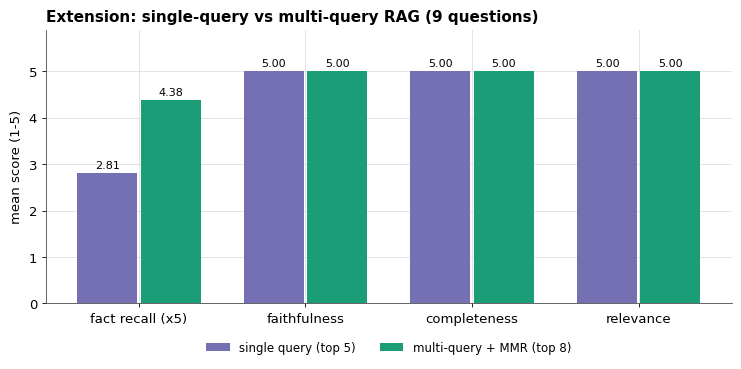

In [20]:
class SubQuestions(BaseModel):
    questions: list[str] = Field(min_length=3, max_length=3)

SUBQ_SYSTEM, SUBQ_PROMPT = kit.register_prompt(
    "sub_questions",
    system="You write search queries for a retrieval system over one IMF country report.",
    template=("Rewrite the question below as {n} short, distinct sub-questions that together cover it. Each should "
              "target one fact or one part of the report, and use the words a report would use (for example "
              "'ECCB', 'NPL', 'primary balance').\n\nQUESTION\n{question}"))

MULTI, MQ_QUERIES = [], {}
for q in QUESTIONS:
    subs = kit.ask(f"rag_multi:subq:{q['id']}", "writer", SUBQ_SYSTEM,
                   SUBQ_PROMPT.format(n=CFG.sub_questions, question=q["q"]), SubQuestions, CFG).questions
    MQ_QUERIES[q["id"]] = subs
    pool = [i for query in [q["q"], *subs] for i in retrieve(query, CFG.pool_per_query)]
    picked = kit.mmr(embed_query(q["q"]), pool, VECTORS, CFG.mq_top_k, CFG.mmr_lambda)
    row = answer_and_score(q, picked, "rag_multi")
    row.update({"sub_questions": subs, "pool_unique": len(set(pool))})
    MULTI.append(row)

METRICS = ["fact_recall", "faithfulness", "completeness", "relevance"]
multi_df = pd.DataFrame(MULTI)
compare = pd.DataFrame({"id": single_df["id"]})
for m in METRICS:
    compare[f"{m}_single"] = single_df[m]
    compare[f"{m}_multi"] = multi_df[m]
    compare[f"{m}_diff"] = (multi_df[m] - single_df[m]).round(2)
compare["page_hit_single"], compare["page_hit_multi"] = single_df["gold_page_hit"], multi_df["gold_page_hit"]
print(compare[["id"] + [f"{m}_{k}" for m in METRICS for k in ("single", "multi")]].to_string(index=False))
EXT_SUMMARY = {mode: {m: round(float(df[m].mean()), 3) for m in METRICS}
               for mode, df in (("single_query", single_df), ("multi_query", multi_df))}
for mode, df in (("single_query", single_df), ("multi_query", multi_df)):
    EXT_SUMMARY[mode]["gold_page_hit"] = round(float(df["gold_page_hit"].dropna().mean()), 3)
    EXT_SUMMARY[mode]["context_chunks"] = int(df["context_chunks"].iloc[0])
print(json.dumps(EXT_SUMMARY, indent=1))
print("Q9 refusal kept with multi-query:", bool(multi_df.iloc[-1]["correct_refusal"]))

kit.plot_style()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
labels = ["fact recall (x5)", "faithfulness", "completeness", "relevance"]
single_vals = [EXT_SUMMARY["single_query"]["fact_recall"] * 5] + [EXT_SUMMARY["single_query"][m] for m in METRICS[1:]]
multi_vals = [EXT_SUMMARY["multi_query"]["fact_recall"] * 5] + [EXT_SUMMARY["multi_query"][m] for m in METRICS[1:]]
x = np.arange(len(labels))
for off, vals, name, colour in ((-0.19, single_vals, f"single query (top {CFG.top_k})", kit.DARK2[2]),
                                (0.19, multi_vals, f"multi-query + MMR (top {CFG.mq_top_k})", kit.DARK2[0])):
    bars = ax.bar(x + off, vals, width=0.36, label=name, color=colour)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(x, labels)
ax.set_ylim(0, 5.9)
kit.tidy_axis(ax, "Extension: single-query vs multi-query RAG (9 questions)", ylabel="mean score (1-5)")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
fig.savefig(Path(CFG.out_fig) / "extension_multiquery.png", dpi=CFG.dpi, bbox_inches="tight")
plt.show()

kit.save_json({"settings": {"sub_questions": CFG.sub_questions, "pool_per_query": CFG.pool_per_query,
                            "mmr_lambda": CFG.mmr_lambda, "multi_top_k": CFG.mq_top_k, "single_top_k": CFG.top_k},
               "summary": EXT_SUMMARY, "per_question": compare.to_dict("records"), "multi_results": MULTI,
               "sub_questions": MQ_QUERIES}, "extension_multiquery", CFG);

## Task 4: tidy data and the dashboard

### 4.1 Wide to long with `pd.melt`

> **What happens here:** the wide tables (one column per series, indicator or theme measure) are melted into long tables with one row per observation, which is the shape the plotting code filters on. Years 2026 onwards are flagged as IMF projections.
>
> **What to look at:** the row counts and the first rows of each long table; they are also saved as JSON.

In [21]:
LAST_ACTUAL = 2025
TS_LONG = (TS_WIDE.reset_index()
           .melt(id_vars="year", var_name="series", value_name="value")
           .dropna(subset=["value"]))
TS_LONG["projection"] = TS_LONG["year"] > LAST_ACTUAL

theme_wide = pd.DataFrame({"theme": kit.THEMES,
                           "lexicon_share_pct": (THEME_TABLE["lexicon_hits"] / THEME_TABLE["lexicon_hits"].sum() * 100).round(1).values,
                           "llm_share_pct": (THEME_TABLE["llm_chunks"] / max(THEME_TABLE["llm_chunks"].sum(), 1) * 100).round(1).values})
THEME_LONG = theme_wide.melt(id_vars="theme", var_name="method", value_name="share_pct")

ind_wide = pd.DataFrame([{"indicator": f, "model": INDICATORS[f], "hand_check": HAND_CHECK[f]["value"]} for f in NUMERIC_FIELDS])
IND_LONG = ind_wide.melt(id_vars="indicator", var_name="source", value_name="value")

judge_wide = pd.DataFrame([{"criterion": c,
                            "summaries_draft": np.mean([r["draft_scores"][c] for r in SUMMARY_ROWS]),
                            "summaries_final": np.mean([r["final_scores"][c] for r in SUMMARY_ROWS]),
                            "executive_final": EXEC_RECORD["final_scores"][c]}
                           for c in ("consistency", "completeness", "factual_alignment")])
JUDGE_LONG = judge_wide.melt(id_vars="criterion", var_name="output", value_name="mean_score")

for name, frame in (("timeseries_long", TS_LONG), ("themes_long", THEME_LONG), ("indicators_long", IND_LONG), ("judge_long", JUDGE_LONG)):
    print(f"{name}: {len(frame)} rows")
    kit.save_json(frame.to_dict("records"), name, CFG)
print(TS_LONG.head(6).to_string(index=False))

timeseries_long: 120 rows
themes_long: 14 rows
indicators_long: 12 rows
judge_long: 9 rows
 year          series  value  projection
 2021 real_gdp_growth    6.9       False
 2022 real_gdp_growth    5.6       False
 2023 real_gdp_growth    4.7       False
 2024 real_gdp_growth    3.5       False
 2025 real_gdp_growth    4.5       False
 2026 real_gdp_growth    3.1        True


### 4.2 Dashboard

> **What happens here:** one figure, a header strip with key findings taken from the executive summary and a 2x3 grid of plots: (A) theme shares from the lexicon and from the LLM labels; (B) CPI inflation against the ECCB policy rate and the time deposit rate, with the IMF projection years shaded; (C) private credit growth against the NPL ratios of banks and credit unions, one point per year; (D) judge scores for the section summaries before and after revision and for the executive summary; (E) the model's indicator values next to my hand-check values; (F) the extension result. ColorBrewer Dark2 colours on white, thin spines, saved at 300 dpi.
>
> **What to look at:** panel B shows that Dominica's policy rate is set for the whole currency union and moved only once (2.0 to 3.0 percent in 2024), while inflation swung from 7.7 percent in 2022 to 2.3 percent in 2025. Panel C shows bank NPLs falling while credit barely grew.

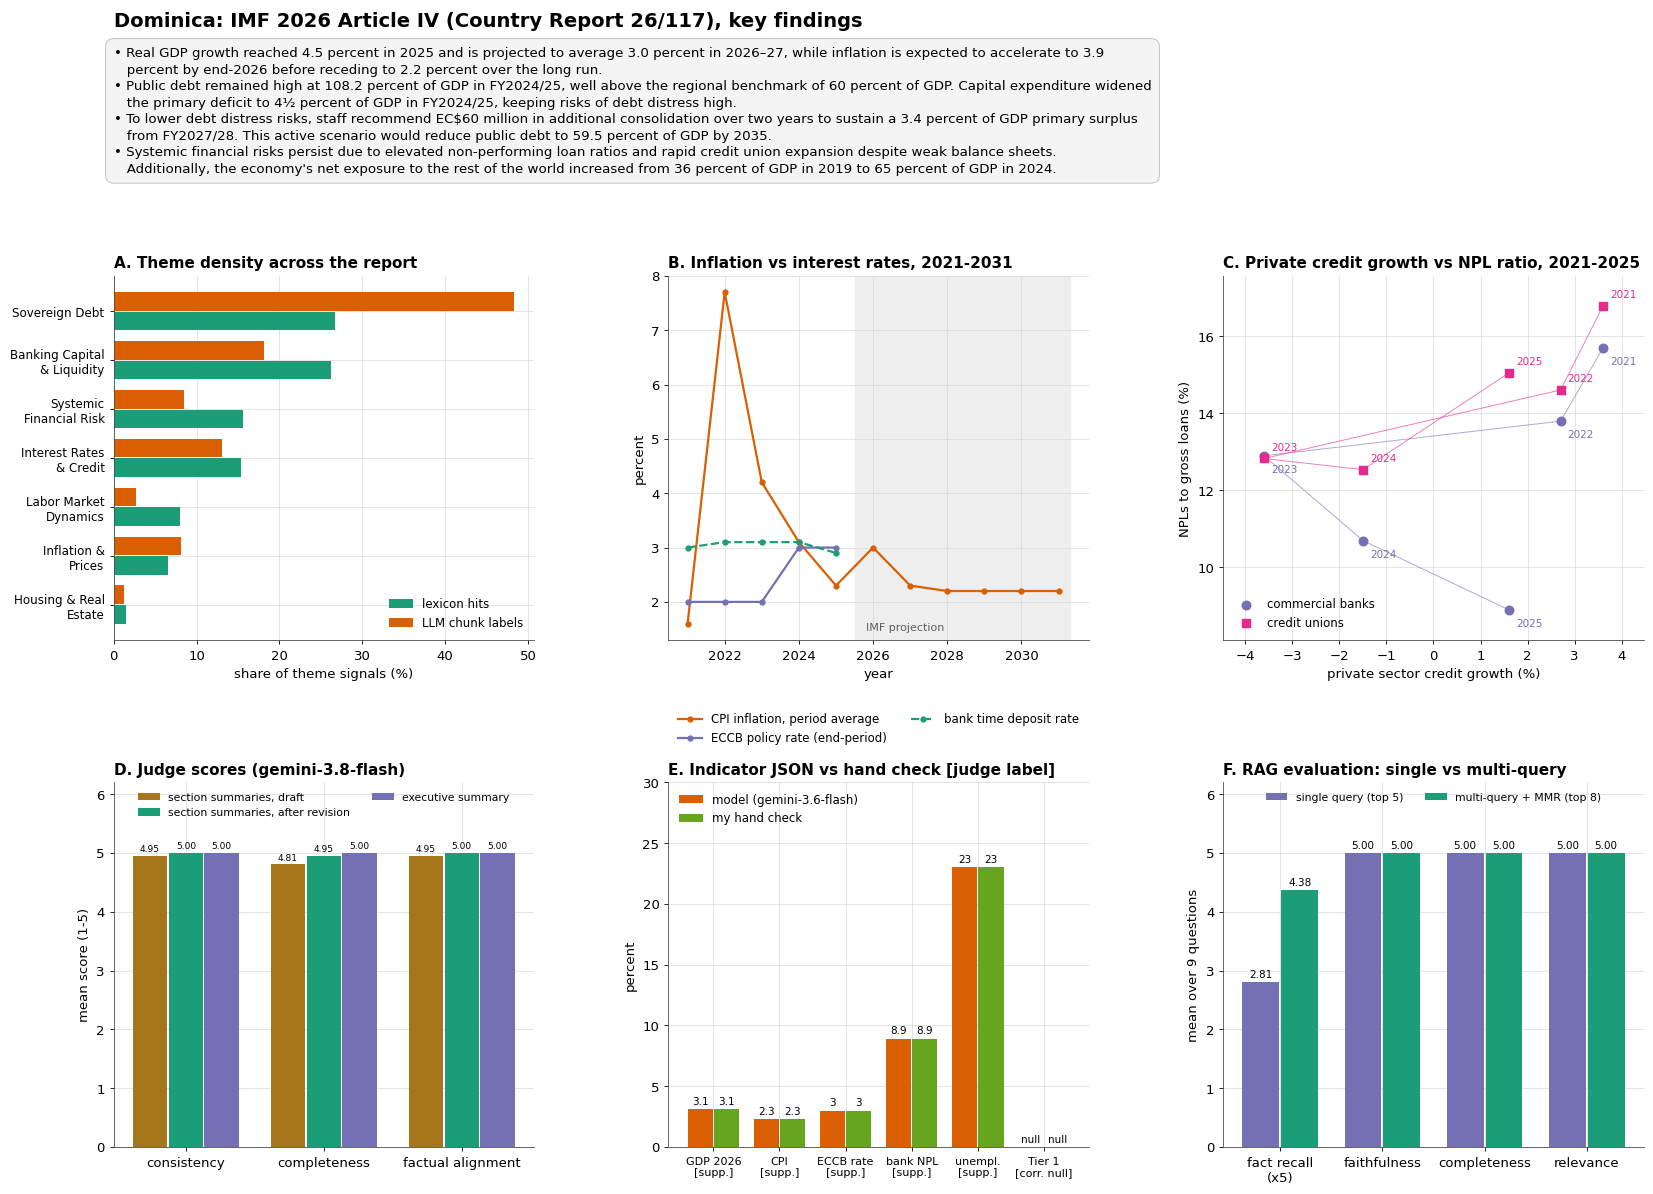

saved outputs/figures/dashboard.png at 300 dpi


In [22]:
kit.plot_style()
C = kit.DARK2
fig = plt.figure(figsize=(17, 12.5))
grid = fig.add_gridspec(3, 3, height_ratios=[0.34, 1, 1], hspace=0.5, wspace=0.32, left=0.085, right=0.985, top=0.97, bottom=0.06)

# header strip: key findings from the executive summary
head = fig.add_subplot(grid[0, :])
head.axis("off")
findings = [textwrap.fill(b["text"], 150, subsequent_indent="   ") for b in EXEC_RECORD["bullets"][:4]]
head.text(0.0, 0.98, f"{CFG.country}: IMF 2026 Article IV (Country Report 26/117), key findings", fontsize=14,
          fontweight="bold", va="top", transform=head.transAxes)
head.text(0.0, 0.70, "\n".join("\u2022 " + f for f in findings), fontsize=9.6, va="top", linespacing=1.35,
          transform=head.transAxes, bbox=dict(boxstyle="round,pad=0.6", fc="#f4f4f4", ec="#bbbbbb", lw=0.6))

# A: theme shares
ax = fig.add_subplot(grid[1, 0])
order = theme_wide.sort_values("lexicon_share_pct")["theme"].tolist()
y = np.arange(len(order))
for off, method, label, colour in ((-0.2, "lexicon_share_pct", "lexicon hits", C[0]), (0.2, "llm_share_pct", "LLM chunk labels", C[1])):
    vals = THEME_LONG[THEME_LONG["method"] == method].set_index("theme").loc[order, "share_pct"]
    ax.barh(y + off, vals, height=0.38, color=colour, label=label)
ax.set_yticks(y, [textwrap.fill(t, 15) for t in order], fontsize=8.6)
kit.tidy_axis(ax, "A. Theme density across the report", xlabel="share of theme signals (%)")
ax.legend(loc="lower right")

# B: inflation vs policy rate
ax = fig.add_subplot(grid[1, 1])
for series, label, colour, style in (("cpi_inflation_avg", "CPI inflation, period average", C[1], "-"),
                                     ("eccb_policy_rate", "ECCB policy rate (end-period)", C[2], "-"),
                                     ("time_deposit_rate", "bank time deposit rate", C[0], "--")):
    part = TS_LONG[TS_LONG["series"] == series]
    ax.plot(part["year"], part["value"], style, marker="o", ms=3.5, lw=1.6, color=colour, label=label)
ax.axvspan(LAST_ACTUAL + 0.5, TS_LONG["year"].max() + 0.3, color="#eeeeee", zorder=0)
ax.text(LAST_ACTUAL + 0.8, ax.get_ylim()[0] + 0.15, "IMF projection", fontsize=8, color="#5e5e5e", va="bottom")
kit.tidy_axis(ax, "B. Inflation vs interest rates, 2021-2031", xlabel="year", ylabel="percent")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)

# C: credit growth vs NPL
ax = fig.add_subplot(grid[1, 2])
credit = SERIES["private_credit_growth"]
for series, label, colour, marker in (("bank_npl_ratio", "commercial banks", C[2], "o"), ("cu_npl_ratio", "credit unions", C[3], "s")):
    yrs = [yr for yr in sorted(credit) if yr <= LAST_ACTUAL and SERIES[series].get(yr) is not None]
    xs, ys = [credit[yr] for yr in yrs], [SERIES[series][yr] for yr in yrs]
    ax.plot(xs, ys, color=colour, lw=0.7, alpha=0.6)
    ax.scatter(xs, ys, color=colour, marker=marker, s=38, label=label, zorder=3)
    dy = 6 if series.startswith("cu") else -12   # credit unions labelled above, banks below, so 2023 does not collide
    for xv, yv, yr in zip(xs, ys, yrs):
        ax.annotate(str(yr), (xv, yv), xytext=(5, dy), textcoords="offset points", fontsize=7.5, color=colour)
kit.tidy_axis(ax, "C. Private credit growth vs NPL ratio, 2021-2025", xlabel="private sector credit growth (%)",
              ylabel="NPLs to gross loans (%)")
ax.margins(x=0.12, y=0.1)
ax.legend(loc="lower left")

# D: judge diagnostics
ax = fig.add_subplot(grid[2, 0])
crit = judge_wide["criterion"].tolist()
x = np.arange(len(crit))
for off, col, label, colour in ((-0.26, "summaries_draft", "section summaries, draft", C[6]),
                                (0, "summaries_final", "section summaries, after revision", C[0]),
                                (0.26, "executive_final", "executive summary", C[2])):
    bars = ax.bar(x + off, judge_wide[col], width=0.25, color=colour, label=label)
    ax.bar_label(bars, fmt="%.2f", fontsize=6.5, padding=1.5)   # two decimals, or 4.95 and 5.00 both print as 5.0
ax.set_xticks(x, [c.replace("_", " ") for c in crit])
ax.set_ylim(0, 6.2)
kit.tidy_axis(ax, f"D. Judge scores ({CFG.judge_model.split('/')[-1]})", ylabel="mean score (1-5)")
ax.legend(loc="upper center", ncol=2, fontsize=7.8)

# E: indicator extraction vs hand check
ax = fig.add_subplot(grid[2, 1])
short = {"gdp_growth_forecast_pct": "GDP 2026", "headline_inflation_rate_pct": "CPI", "central_bank_policy_rate_pct": "ECCB rate",
         "non_performing_loan_ratio": "bank NPL", "unemployment_rate_pct": "unempl.", "tier_1_capital_ratio": "Tier 1"}
x = np.arange(len(NUMERIC_FIELDS))
for off, source, label, colour in ((-0.2, "model", f"model ({CFG.writer_model.split('/')[-1]})", C[1]), (0.2, "hand_check", "my hand check", C[4])):
    vals = IND_LONG[IND_LONG["source"] == source].set_index("indicator").loc[NUMERIC_FIELDS, "value"]
    heights = [0 if v is None or pd.isna(v) else float(v) for v in vals]
    bars = ax.bar(x + off, heights, width=0.38, color=colour, label=label)
    for b, v in zip(bars, vals):
        txt = "null" if v is None or pd.isna(v) else f"{float(v):g}"
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.4, txt, ha="center", fontsize=7.5, rotation=0)
abbrev = {"SUPPORTED": "supp.", "NOT_SUPPORTED": "not supp.", "CORRECT_NULL": "corr. null", "WRONG_NULL": "wrong null"}
verdicts = [abbrev.get(audit_map[f].label, "") if f in audit_map else "" for f in NUMERIC_FIELDS]
ax.set_xticks(x, [f"{short[f]}\n[{v}]" for f, v in zip(NUMERIC_FIELDS, verdicts)], fontsize=8)
ax.set_ylim(0, max(30, max(float(v) for v in IND_LONG["value"] if v is not None and not pd.isna(v)) * 1.25))
kit.tidy_axis(ax, "E. Indicator JSON vs hand check [judge label]", ylabel="percent")
ax.legend(loc="upper left")

# F: extension
ax = fig.add_subplot(grid[2, 2])
labels = ["fact recall\n(x5)", "faithfulness", "completeness", "relevance"]
x = np.arange(len(labels))
for off, vals, name, colour in ((-0.19, single_vals, f"single query (top {CFG.top_k})", C[2]),
                                (0.19, multi_vals, f"multi-query + MMR (top {CFG.mq_top_k})", C[0])):
    bars = ax.bar(x + off, vals, width=0.36, color=colour, label=name)
    ax.bar_label(bars, fmt="%.2f", fontsize=7.5, padding=1.5)
ax.set_xticks(x, labels)
ax.set_ylim(0, 6.2)
kit.tidy_axis(ax, "F. RAG evaluation: single vs multi-query", ylabel="mean over 9 questions")
ax.legend(loc="upper center", ncol=2, fontsize=7.8)

DASH_PATH = Path(CFG.out_fig) / "dashboard.png"
fig.savefig(DASH_PATH, dpi=CFG.dpi)
plt.show()
print(f"saved {DASH_PATH} at {CFG.dpi} dpi")

## Run record

> **What happens here:** every prompt template registered above is printed in full (system instruction and user template), followed by the call log: one row per request with the step, the role, the model, whether it was a live call or a cached reply, the seconds it took and the output tokens. Both are saved.
>
> **What to look at:** the live and cached counts. A second *Run all* with the cache in place should show 0 live calls.

In [23]:
for name, p in kit.PROMPTS.items():
    print(f"=== PROMPT {name} ===\n[system]\n{p['system']}\n[template]\n{p['template']}\n")

log_df = pd.DataFrame(kit.CALL_LOG)
log_df["stage"] = log_df["step"].str.split(":").str[0]
print(log_df.groupby(["stage", "role", "model"]).agg(calls=("live", "size"), live=("live", "sum"),
                                                      seconds=("seconds", "sum"), out_tokens=("out_tokens", "sum")).to_string())
RUN_SUMMARY = kit.log_summary()
print("\n" + json.dumps(RUN_SUMMARY, indent=1))
pd.set_option("display.max_rows", 400)
print(log_df[["step", "role", "model", "live", "seconds", "out_tokens"]].to_string(index=False))
kit.save_json(kit.CALL_LOG, "call_log", CFG)
kit.save_json({"summary": RUN_SUMMARY, "prompts": kit.PROMPTS, "settings": CFG._asdict(),
               "pdf_sha256": CLEAN_REPORT["pdf_sha256"]}, "run_record", CFG);

=== PROMPT section_summary ===
[system]
You summarise sections of an IMF country report for an economist who has not read it. Use only the text you are given. Copy every number exactly as printed and say which year or fiscal year it refers to. Write plain British English in full sentences, with no bullet points.
[template]
Section: {title} (PDF pages {pages}).
Write a summary of FEWER than {limit} words. Cover the main finding, the numbers that support it and any risk or policy advice the section gives. If the section is mostly charts or statistical tables, say what they show and quote the two or three most telling figures.

SECTION TEXT
{text}

=== PROMPT summary_judge ===
[system]
You audit summaries of IMF report sections. You are strict and specific. Compare the summary with the source text sentence by sentence before you score.
[template]
Score the summary from 1 (poor) to 5 (excellent) on three criteria.
consistency: nothing in the summary contradicts the source.
completeness: th

### Files written by this notebook

| File | Content |
|---|---|
| `outputs/json/cleaning_report.json` | cleaning fix counts and examples |
| `outputs/json/sections.json`, `chunks.json` | detected sections; chunks with pages and token counts |
| `outputs/json/section_summaries.json` | summaries, judge scores before and after revision |
| `outputs/json/executive_summary.json` | bullets, judge scores, number check |
| `outputs/json/themes.json`, `themes_long.json` | lexicon and LLM theme counts, Spearman rho |
| `outputs/json/strengths_vulnerabilities.json` | final 5-7 + 5-7 items and every checked item |
| `outputs/json/indicators.json` | the indicator JSON in the target schema |
| `outputs/json/indicator_evidence.json`, `indicator_audit.json` | evidence, fallbacks, judge labels, hand check |
| `outputs/json/timeseries.json`, `timeseries_long.json` | series parsed from Tables 1, 4, 5a and 5b with cross-checks |
| `outputs/json/rag_eval.json`, `extension_multiquery.json` | RAG and extension results |
| `outputs/json/call_log.json`, `run_record.json` | every call and every prompt |
| `outputs/figures/dashboard.png`, `extension_multiquery.png` | figures at 300 dpi |